In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors

In [3]:

figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

palatte_behavior_dict = load_pickle(figure_config_root+'palatte_behavior_dict')
palatte_behavior_dict['M_RFP_vel_norm']=palatte_behavior_dict['M_RFP_vel']
palatte_behavior_dict['M_LFP_vel_norm'] = palatte_behavior_dict['M_LFP_vel']
palatte_behavior_dict['M_whisking'] = 'slateblue'

fetch_path_data = str(FIGURES / "figure6") + "/"

sunset_cmap = load_pickle(figure_config_root+'sunset_cmap')

In [4]:
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP'] # the order matters
M1_bdps_w_order = [ 'RFP', 'LFP', 'RHP', 'LHP' ]
all_bdps_w_order = [ 'RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']

# LICK

In [5]:
t_total = 36
array_S1,array_M1,array_M2,array_all = np.empty((8,t_total,0)),np.empty((4,t_total,0)),np.empty((8,t_total,0)),np.empty((42,t_total,0))
list_behavior = ['M_licking', 'M_LFP_vel', 'M_RFP_vel', 'M_rotf']
M_licking, M_LFP_vel, M_RFP_vel, M_rotf = np.empty((t_total,0)),np.empty((t_total,0)),np.empty((t_total,0)),np.empty((t_total,0))
array_cov_S1M1,array_cov_S1M2,array_cov_M1M2=np.empty((0,8,4)),np.empty((0,8,8)),np.empty((0,8,4))
wco_pot=pd.DataFrame() 

dict_contours_per_mouse = {}
dict_blended_movie_per_mouse = {}
dict_AVG_full_jrgeco_2_save_per_mouse = {}

amplitude_data_dict = {}
for mouse_id in ['cm229','cm241','cm242']:
    pd_temp = pd.DataFrame()
    dict_here = load_pickle(figure_config_root+'M2-S1M1_area_segment_'+mouse_id)
    dict_contours_per_mouse[mouse_id] = dict_here['contours']
    dict_all = load_pickle(fetch_path_data+'dict_all_lick_'+mouse_id)
    dict_all_stats = dict_all['dict_all_stats']
    dict_all_data = dict_all['dict_all_data']
    
    all_bdps_w_order = dict_all_stats['all_bdps_w_order']
    T_PRE = dict_all_data['T_PRE']
    time_range_to_cut = np.arange(T_PRE-18,T_PRE+18)

    array_S1_this = dict_all_data['array_S1'][:,time_range_to_cut,:]
    array_M1_this = dict_all_data['array_M1'][:,time_range_to_cut,:]
    array_M2_this = dict_all_data['array_M2'][:,time_range_to_cut,:]
    array_S1 = np.append(array_S1,array_S1_this,axis=2)
    array_M1 = np.append(array_M1,array_M1_this,axis=2)
    array_M2 = np.append(array_M2,array_M2_this,axis=2)
    array_all = np.append(array_all,dict_all_data['H_nnls_bouts'][:,time_range_to_cut,:],axis=2)

    ind_licking = range(18,18+10)
    # FIX: use this mouse's own bouts only. Previously sliced from the cumulative array_S1/M1/M2
    # (built up across the mouse loop), which silently mixed every earlier mouse's bouts into the
    # 2nd/3rd mouse's amplitude_data_dict entry -- see cell 5's note.
    amplitude_data_dict[mouse_id]= {'S1': np.mean(array_S1_this[:,ind_licking,:],axis=1),
                   'M2': np.mean(array_M2_this[:,ind_licking,:],axis=1),
                    'M1': np.mean(array_M1_this[:,ind_licking,:],axis=1),  }

    
    for behavior in list_behavior:
        exec("{} = np.append({},dict_all_data['dict_behaviors'][behavior][time_range_to_cut,:],axis=1)".format(behavior,behavior))

    for cov_array_type in ['S1M2']:
        exec("array_cov_{} = np.append(array_cov_{},dict_all_stats['array_cov_'+cov_array_type],axis=0)".format(cov_array_type,cov_array_type))
        # Assemble coherence STATS pot
        for i_bdp, bdp in enumerate(all_bdps_w_order):  
            diff_temp=pd.DataFrame(columns=['wco','mouse','bdp','S1M1_or_S1M2'])
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,i_bdp,i_bdp]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])
            
    for cov_array_type in ['S1M1']:
        #======
        ss = dict_all_stats['array_cov_'+cov_array_type].shape
        cov_S1M1 = np.zeros((ss[0],8,4));cov_S1M1[:]=np.nan
        indices_S1 = range(len(all_bdps_w_order))
        indices_M1 = [all_bdps_list_M1.index(item) for item in M1_bdps_w_order]
        cov_S1M1[np.ix_(range(ss[0]),range(8), range(4))] = dict_all_stats['array_cov_'+cov_array_type][np.ix_(range(ss[0]),indices_S1, indices_M1)]           
        
        exec("array_cov_{} = np.append(array_cov_{},cov_S1M1,axis=0)".format(cov_array_type,cov_array_type))
        for i_bdp_M1, bdp_M1 in enumerate(all_bdps_list_M1):
            ind_in_all_bdps_list = M1_bdps_w_order.index(bdp_M1)
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,ind_in_all_bdps_list,i_bdp_M1]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp_M1
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])
        
    for cov_array_type in ['M1M2']:
        exec("array_cov_{} = np.append(array_cov_{},dict_all_stats['array_cov_'+cov_array_type],axis=0)".format(cov_array_type,cov_array_type))
        for i_bdp_M1, bdp_M1 in enumerate(all_bdps_list_M1):
            ind_in_all_bdps_list = all_bdps_w_order.index(bdp_M1)
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,ind_in_all_bdps_list,i_bdp_M1]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp_M1
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])    
        
    if mouse_id == 'cm241':
        scaling_factor = 3.3
    elif mouse_id == 'cm242':
        scaling_factor = 1.5
    elif mouse_id == 'cm229':
        scaling_factor = 1.5
        
    dict_blended_movie_per_mouse[mouse_id] = np.mean(dict_all_data['blended_movie_2_save'][:,:,:,T_PRE:T_PRE+10]*scaling_factor,-1)
    dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id] = np.mean(dict_all_data['AVG_full_jrgeco_2_save'][:,:,T_PRE:T_PRE+10],-1)     
            
    print(mouse_id,': ',dict_all_data['array_S1'].shape[-1])


cm229 :  18
cm241 :  12
cm242 :  13


In [6]:
dict_all_data['dict_behaviors'].keys()

dict_keys(['M_licking', 'M_LFP_vel', 'M_RFP_vel', 'M_rotf'])

In [7]:
# --- 1. DataFrame Assembly ---
rows = []
all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']

# Use this ONLY for unpacking the matrix correctly!
m1_raw_data_order = ['RFP', 'RHP', 'LFP', 'LHP'] 

for mouse_id, region_dict in amplitude_data_dict.items():
    for region_name, matrix in region_dict.items():
        if region_name == 'M1':
            current_bdp_list = m1_raw_data_order
        else:
            current_bdp_list = all_bdps_w_order
            
        for bdp_idx, bdp in enumerate(current_bdp_list):
            for bout_idx, value in enumerate(matrix[bdp_idx]):
                rows.append({
                    'mouse_id': mouse_id, 'region': region_name,
                    'bdp': bdp, 'bout': bout_idx, 'value': value
                })

df = pd.DataFrame(rows)

In [8]:
GRAND_DF = pd.DataFrame()
df['movement_type'] = 'lick'
GRAND_DF = pd.concat([GRAND_DF, df])

In [9]:
# wco_pot  = wco_pot[np.logical_or(wco_pot['S1M1_or_S1M2']=='S1M2',
#                                  wco_pot['S1M1_or_S1M2']=='S1M1')]
# # wco_pot  = wco_pot[wco_pot['S1M1_or_S1M2']=='S1M2']

In [10]:
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1

all_bdps_nnls = all_bdps + ['globalM2','globalCortex']


palatte_dict['RALM'] = palatte_dict['ALM']
palatte_dict['LALM'] = 'bisque'
palatte_dict['RRSP'] = palatte_dict['RSP']
palatte_dict['LRSP'] = 'sandybrown'
palatte_dict['RFP_M1_extra'] = 'tab:olive'
palatte_dict['LFP_M1_extra'] = 'tab:cyan'

# palatte_dict['RholeMOp'] = 'tab:green'
palatte_dict['LholeMOp'] = '#ff964f' #pastel orange
palatte_dict['RholeMOp'] = '#ff964f' #pastel orange

palatte_dict['RT'] = 'darkseagreen'
palatte_dict['LT'] = 'olivedrab'

palatte_dict['Rposterior'] = 'palegreen'
palatte_dict['Lposterior'] = 'greenyellow'
palatte_dict['globalM2']= 'gray'

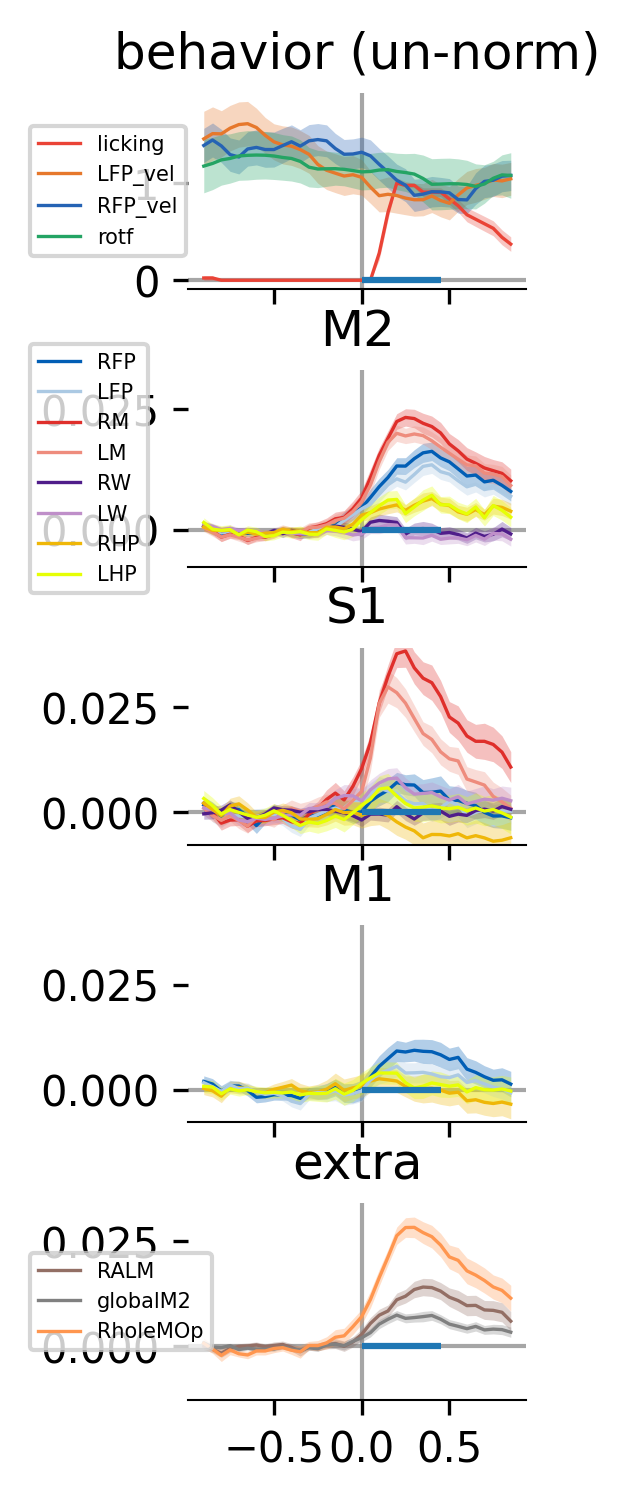

In [11]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;


# webcam image
# x_start = x_offset
# x_stop = x_start+8
# ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
x_start = x_offset
x_stop = x_start+5
# jrgeco snapshots for 'run'''''
# ax1 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# # colorbar for jrgeco snapshot
# x_start = x_stop
# x_stop = x_start+1
# ax991 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# time courses for behaviors
x_start = x_stop+1
x_stop = x_start+5
ax5 = fig.add_subplot(gs[y_offset-5:y_offset-2,x_start:x_stop])
# time courses for M2
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset-1:y_offset+2,x_start:x_stop])
# time courses for S1
x_start = x_start
x_stop = x_start+5
ax3 = fig.add_subplot(gs[y_offset+3:y_offset+6,x_start:x_stop])
# time courses for M1
x_start = x_start
x_stop = x_start+5
ax4 = fig.add_subplot(gs[y_offset+7:y_offset+10,x_start:x_stop])


# time courses for EXTRA
x_start = x_start
x_stop = x_start+5
ax6 = fig.add_subplot(gs[y_offset+11:y_offset+14,x_start:x_stop])


# # webcam
# ax0.imshow(dict_webcam_img['lick'],cmap='gray')


T_total = time_range_to_cut.shape[0]
fs_here = 20
t_ax_trimmed = np.divide(range(-18,T_total-18),fs_here)
# time courses -M2
for i_bdp,bdp_name in enumerate(all_bdps_w_order):
    data_here = array_M2[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax2.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
# time courses -S1    
for i_bdp,bdp_name in enumerate(all_bdps_w_order):
    data_here = array_S1[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax3.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax3.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
# time courses -M1    
for i_bdp,bdp_name in enumerate(all_bdps_list_M1):
    data_here = array_M1[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax4.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax4.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
# time courses - behaviors
colors2=sns.color_palette()
for i_choice_behavior,behavior_here in enumerate(list_behavior):
    exec("data_here = {}".format(behavior_here))
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax5.plot(t_ax_trimmed,avg,label=behavior_here[2:],color=palatte_behavior_dict[behavior_here],linewidth=0.8)
    ax5.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_behavior_dict[behavior_here],alpha=0.3,lw=0)

# time courses - EXTRA
for i_bdp,bdp_name in enumerate([ 'RALM','globalM2','RholeMOp']):
    ind_in_list = all_bdps_nnls.index(bdp_name)
    data_here = array_all[ind_in_list,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax6.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax6.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
    

# # ax2.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)
# # ax3.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)

# # jrgeco
# sbp1 = ax1.imshow(np.mean(np.mean(dict_full_jrgeco_dbsl_mice['cm229'][:,:,T_PRE_all_mice:T_PRE_all_mice+2,:],axis=2),axis=-1),cmap='icefire',vmin=-0.04,vmax=0.04)
# # add scatter plot
# for i_bdp, bdp_S1 in enumerate(list_choice_M2):
#     region_number = M1_ind_from_coherence[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker="D", s=6, c=palatte_dict[bdp_S1], zorder=2)
#     region_number = sensory_ind_here[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker='*', s=6, c=palatte_dict[bdp_S1], zorder=2)
#     ax1.scatter(node_coords_M2[bdp_S1][0], node_coords_M2[bdp_S1][1], s=3, c=palatte_dict[bdp_S1], zorder=2)

# #color bar
# cb = fig.colorbar(sbp1, cax=ax991,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
# cb.ax.tick_params(labelsize=7,length=2,color='black')
# cb.ax.yaxis.tick_right()       
# cb.outline.set_edgecolor('black')
# cb.outline.set_linewidth(0.5)
# tick_locator = ticker.MaxNLocator(nbins=3)
# cb.locator = tick_locator
# cb.update_ticks()
# ax991.set_aspect(100);ax991.set_anchor('W')


# ######
    
# exec("ax{}.set_xticks([]);ax{}.set_yticks([]);ax{}.set_xticks([]);ax{}.set_yticks([])".format(1,1,1,1))
# ax1.set_xlim([15,256]);ax1.set_ylim([256,15])
ax5.set_xticklabels([])
ax2.set_xticklabels([])
ax3.set_xticklabels([])
ax4.set_xticklabels([])

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,7):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
            
for i_ax in range(2,7):
    exec("ax{}.axvline(t_ax_trimmed[18],linewidth=1,color='gray',alpha=0.7,zorder=-999999) ".format(i_ax)) 
    exec("ax{}.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999999) ".format(i_ax)) 


for axis in ['top','right','left']:
    for i_ax in range(2,7):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
        
ax2.set_title('M2')
ax3.set_title('S1')
ax4.set_title('M1')

ax3.set_ylim([-0.007695708547598934, 0.03910883774605999])
ax4.set_ylim([-0.007695708547598934, 0.03910883774605999])
ax2.set_ylim([-0.007695708547598934, 0.0330883774605999])
ax6.set_ylim([-0.017695708547598934+0.005, 0.02910883774605999+0.005])

ax5.set_title('behavior (un-norm)')
ax6.set_title('extra')
ax2.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)
ax5.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)
ax6.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)


ax3.hlines(y=0.0,xmin=t_ax_trimmed[ind_licking[0]],xmax=t_ax_trimmed[ind_licking[-1]])
ax4.hlines(y=0.0,xmin=t_ax_trimmed[ind_licking[0]],xmax=t_ax_trimmed[ind_licking[-1]])
ax5.hlines(y=0.0,xmin=t_ax_trimmed[ind_licking[0]],xmax=t_ax_trimmed[ind_licking[-1]])
ax2.hlines(y=0.0,xmin=t_ax_trimmed[ind_licking[0]],xmax=t_ax_trimmed[ind_licking[-1]])
ax6.hlines(y=0.0,xmin=t_ax_trimmed[ind_licking[0]],xmax=t_ax_trimmed[ind_licking[-1]])


plt.savefig('fig7-lick-part1.svg',format='svg',dpi=300)

In [12]:
# Plot function updated to fix the IndexError
def plot_with_stats(ax, region, order_list):
    df_region = df[df['region'] == region]
    
    # Safety check in case the region string doesn't match your dataframe exactly
    if len(df_region) == 0:
        print(f"WARNING: No data found for region '{region}'!")
        return

    # Plot bars with palette manually
    sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
                order=order_list,
                palette=palatte_dict, errorbar=None, zorder=1)

    # Overlay individual data points
    # ---> FIX: Removed dodge=True which crashes without a hue parameter
    sns.stripplot(ax=ax, data=df_region, x='bdp', y='value',
                  order=order_list, color='tab:blue',
                  size=1, jitter=True, zorder=3, alpha=0.3)

    # Bring bar borders to top layer
    for bar in ax.patches:
        bar.set_edgecolor('black')
        bar.set_linewidth(0.5)
        bar.set_zorder(2)
        
    # Manually draw error bars (mean ± SEM)
    for i, bdp in enumerate(order_list):
        values = df_region[df_region['bdp'] == bdp]['value']
        # Only calculate and plot error bars if there is data for this body part
        if not values.empty:
            mean = values.mean()
            sem = values.sem()
            ax.errorbar(i, mean, yerr=sem, fmt='none', ecolor='black',
                        capsize=2, capthick=0.3, linewidth=1, zorder=4)

    ax.set_title(f"{region} Region")

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/2095591061.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/2095591061.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/2095591061.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',


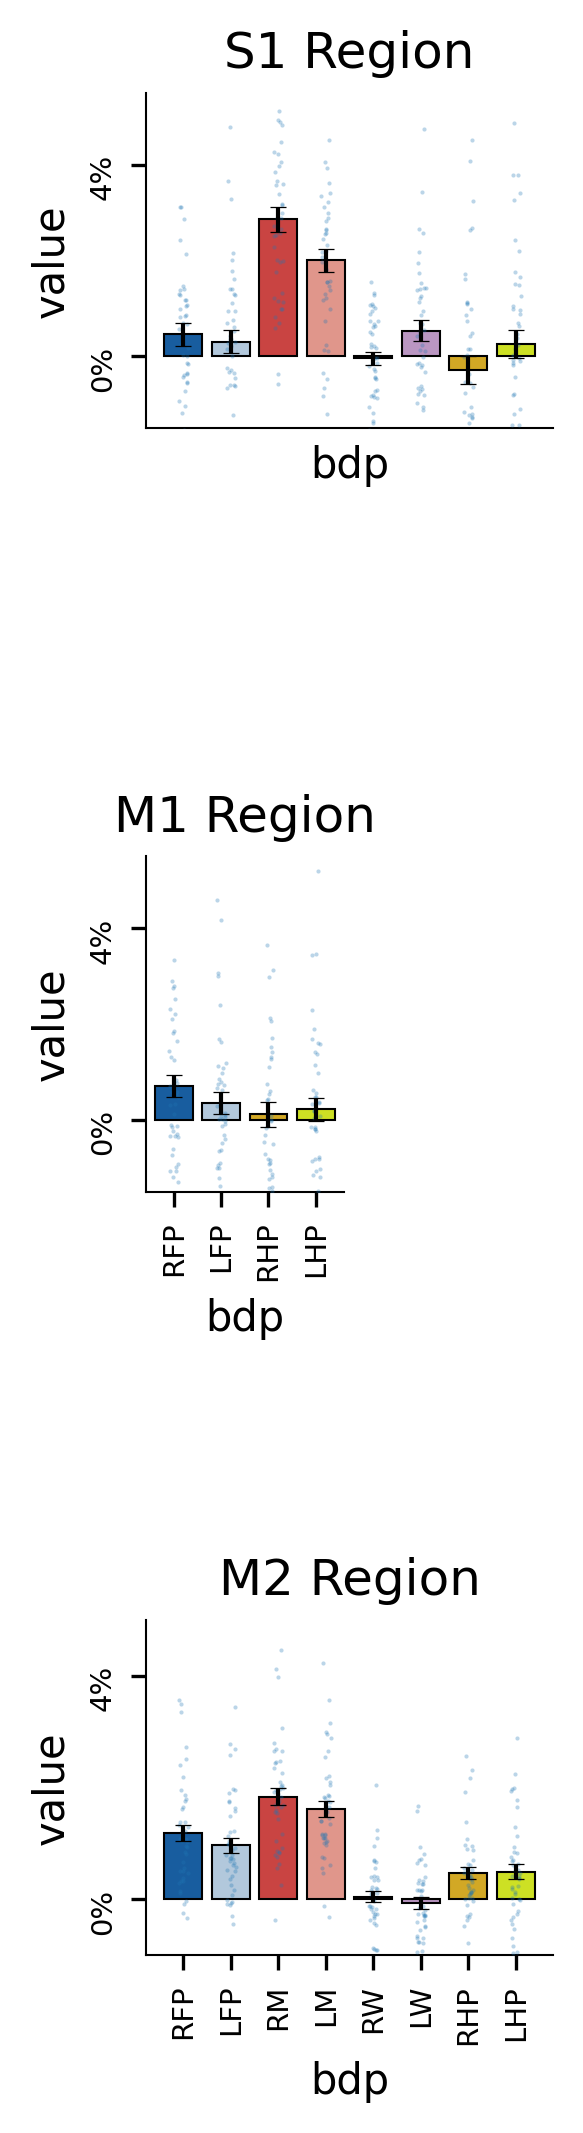

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from decimal import Decimal
from statannot import add_stat_annotation

plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

fmt = lambda x, pos: '{:.0%}'.format(x)

fig = plt.figure(figsize=(30, 30), dpi=300)
gs = GridSpec(100, 100)

y_offset = 20
x_offset = 20
x_start = x_offset

# Set widths to allow clean halving (6 for full, 3 for half)
width_full = 6
width_half = 3

# Define the 3 subplots stacked vertically
ax0 = fig.add_subplot(gs[y_offset : y_offset+5, x_start : x_start+width_full])        # S1
ax1 = fig.add_subplot(gs[y_offset+11 : y_offset+16, x_start : x_start+width_half])    # M1 (Half width)
ax2 = fig.add_subplot(gs[y_offset+22 : y_offset+27, x_start : x_start+width_full])    # M2

# Define bodypart orders
all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']
m1_display_order = ['RFP', 'LFP', 'RHP', 'LHP']


# Plot the 3 regions
plot_with_stats(ax0, "S1", all_bdps_w_order)
plot_with_stats(ax1, "M1", m1_display_order)
plot_with_stats(ax2, "M2", all_bdps_w_order)

# Y-axis formatting
ax0.set_ylim([-0.015, 0.055])       
ax1.set_ylim([-0.015, 0.055])  # Matched M1 limits to S1 for consistency
ax2.set_ylim([-0.01, 0.05])

for ax in [ax0, ax1, ax2]:
    ax.set_yticks([0.00, 0.04])
    ax.set_yticks(ax.get_yticks(), ax.get_yticklabels(), rotation=90, fontsize=7)
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))

# X-axis formatting (S1 gets no ticks, M1 and M2 get rotated ticks)
ax0.set_xticks([])
ax1.set_xticks(ax1.get_xticks(), ax1.get_xticklabels(), rotation=90, fontsize=7)
ax2.set_xticks(ax2.get_xticks(), ax2.get_xticklabels(), rotation=90, fontsize=7)

# Spine formatting (Replaced exec loops with safer list iteration)
for axis in ['top', 'right', 'left', 'bottom']:
    for ax in [ax0, ax1, ax2]:
        try:
            ax.spines[axis].set_linewidth(0.5)
        except:
            continue

for axis in ['top', 'right']:
    for ax in [ax0, ax1, ax2]:
        ax.spines[axis].set_linewidth(0)

plt.savefig('fig7-lick-part4.svg', format='svg', dpi=300)

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/564577049.py:95: UserWarning: The palette list has more values (8) than needed (3), which may not be intended.
  sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/564577049.py:95: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',


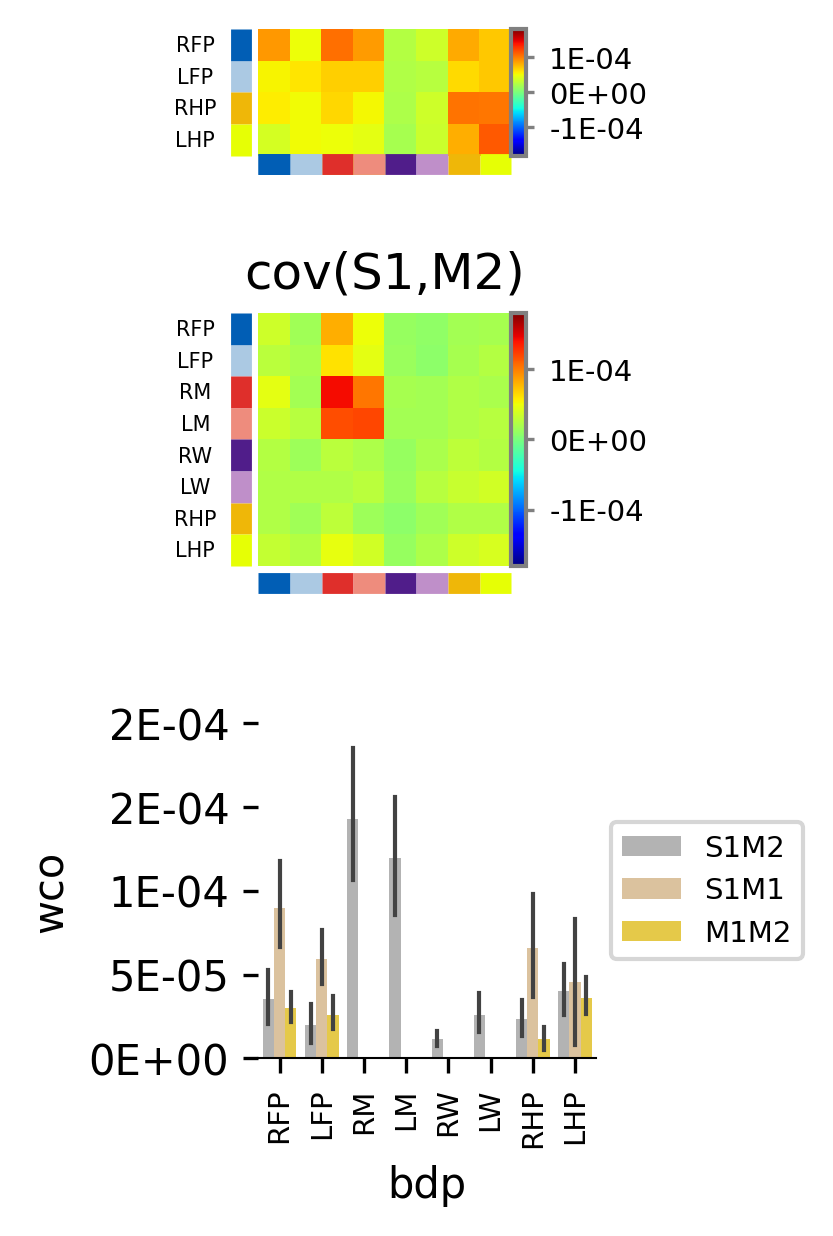

In [14]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from decimal import Decimal
fmt = lambda x, pos: '%.0E' % Decimal(x)

# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = y_offset
x_stop = x_start+4
ax0 = fig.add_subplot(gs[y_offset:y_offset+4,x_start:x_stop])
x_start = x_start
x_stop = x_start+4
ax1 = fig.add_subplot(gs[y_offset+5:y_offset+9,x_start:x_stop])
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset+11:y_offset+16,x_start:x_stop])

#=====

divnorm=colors.TwoSlopeNorm(vmin=-0.00018, vcenter=0., vmax=0.00018) 
i_ax=0
exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M1,0).T,cmap='jet',norm=divnorm)".format(i_ax,i_ax))
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=2,color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
start=-0.5;
for bdp in M1_bdps_w_order:
    stop = start + 1
    ax0.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    ax0.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=5, clip_on=False,solid_capstyle='butt')
    # ax0.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    if i_ax == 0:
        ax0.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=5, va="top")
    start = stop
        
start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax0.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    start = stop
    
#####
divnorm=colors.TwoSlopeNorm(vmin=-0.00018, vcenter=0., vmax=0.00018) 
i_ax = 1

exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M2,0).T,cmap='jet',norm=divnorm)".format(i_ax,i_ax))

from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=2,color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)

exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))

start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax1.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    ax1.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=5, clip_on=False,solid_capstyle='butt')
    # ax1.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=5, va="top")
    start = stop
    
for i_ax in range(2):
    exec("ax{}.axis('off')".format(i_ax))
    
# ax0.set_title('cov(S1,M1)')
ax1.set_title('cov(S1,M2)')


sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',
            hue='S1M1_or_S1M2',
            palette=sns.color_palette("Set2")[::-1],
           errorbar=('ci', 95),errwidth=1)
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=7)

ax2.yaxis.set_major_formatter(FuncFormatter(fmt))
ax2.set_xticks(ax2.get_xticks(), ax2.get_xticklabels(), rotation=90,fontsize=7)



for axis in ['top','right','left','bottom']:
    for i_ax in range(2,3):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue

for axis in ['top','right','left']:
    for i_ax in range(2,3):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
        
ax2.set_ylim([0.0, 0.0002])

plt.savefig('fig7-lick-part2.svg',format='svg',dpi=300)

# brain maps

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.2892032].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.8383768].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.1697038].


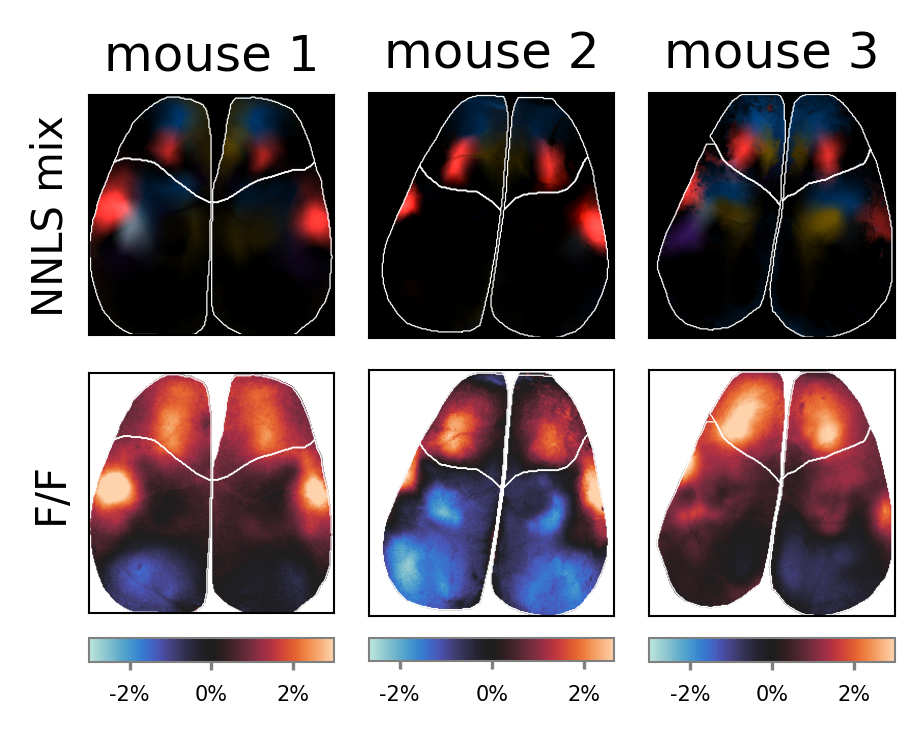

In [15]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;



x_start = x_offset
x_stop = x_start+4
y_start = y_offset
y_stop = y_start+4
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+4
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
    
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+1
for i_ax in range(3,6):
    exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
#===================
for i_mouse,mouse_id in enumerate(['cm229','cm241','cm242']):
    exec("ax{}.imshow(dict_blended_movie_per_mouse[mouse_id])".format(i_mouse))
    if mouse_id == 'cm241':
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id],vmin=-0.02,vmax=0.02,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    else:
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id],vmin=-0.03,vmax=0.03,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    contours = dict_contours_per_mouse[mouse_id]
    for contour in contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))
    for contour in contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))




ax3.set_xlim([21,256]);ax3.set_ylim([248,18]);ax0.set_xlim([21,256]);ax0.set_ylim([248,18])#cm229
ax4.set_xlim([19,256]);ax4.set_ylim([237,0]);ax1.set_xlim([19,256]);ax1.set_ylim([237,0])#cm241
ax5.set_xlim([19,256]);ax5.set_ylim([237,0]);ax2.set_xlim([19,256]);ax2.set_ylim([237,0])#cm241



for i_ax in range(3,6):
    exec("cb = fig.colorbar(img{}, cax=ax99{},fraction=0.2,orientation='horizontal',format=FuncFormatter(fmt));".format(i_ax,i_ax))
    cb.ax.tick_params(labelsize=5,length=2,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(0.5)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    if i_ax == 4:
        exec("ax99{}.set_aspect(0.0039)".format(i_ax))
    else:
        exec("ax99{}.set_aspect(0.006)".format(i_ax))
    exec("ax99{}.set_anchor('N')".format(i_ax))


for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue 
            
ax0.set_title('mouse 1');ax1.set_title('mouse 2');ax2.set_title('mouse 3')

ax3.set_ylabel('F/F');#ax4.set_title('F/F');ax5.set_title('F/F')
ax0.set_ylabel('NNLS mix');

plt.subplots_adjust(wspace=1)
plt.savefig('fig7-lick-part3.svg',format='svg',dpi=300)


# RUN

In [16]:
t_total = 110
array_S1,array_M1,array_M2,array_all = np.empty((8,t_total,0)),np.empty((4,t_total,0)),np.empty((8,t_total,0)),np.empty((42,t_total,0))

list_behavior = ['M_LFP_vel_norm', 'M_RFP_vel_norm', 'M_rotf']
M_LFP_vel_norm, M_RFP_vel_norm, M_rotf = np.empty((t_total,0)),np.empty((t_total,0)),np.empty((t_total,0))
array_cov_S1M1,array_cov_S1M2,array_cov_M1M2=np.empty((0,8,4)),np.empty((0,8,8)),np.empty((0,8,4))
wco_pot=pd.DataFrame() 

dict_contours_per_mouse = {}
dict_blended_movie_per_mouse = {}
dict_AVG_full_jrgeco_2_save_per_mouse = {}

amplitude_data_dict = {}
for mouse_id in ['cm229','cm125','cm126']:
    dict_here = load_pickle(figure_config_root+'M2-S1M1_area_segment_'+mouse_id)
    dict_contours_per_mouse[mouse_id] = dict_here['contours']
    dict_all = load_pickle(fetch_path_data+'dict_all_run_'+mouse_id)
    dict_all_stats = dict_all['dict_all_stats']
    dict_all_data = dict_all['dict_all_data']
    
    all_bdps_w_order = dict_all_stats['all_bdps_w_order']
    T_PRE = dict_all_data['T_PRE']
    time_range_to_cut = np.arange(T_PRE-30,T_PRE+80)

    array_S1_this = dict_all_data['array_S1'][:,time_range_to_cut,:]
    array_M1_this = dict_all_data['array_M1'][:,time_range_to_cut,:]
    array_M2_this = dict_all_data['array_M2'][:,time_range_to_cut,:]
    array_S1 = np.append(array_S1,array_S1_this,axis=2)
    array_M1 = np.append(array_M1,array_M1_this,axis=2)
    array_M2 = np.append(array_M2,array_M2_this,axis=2)
    array_all = np.append(array_all,dict_all_data['H_nnls_bouts'][:,time_range_to_cut,:],axis=2)

    ind_running = range(30,30+40)
    # FIX: use this mouse's own bouts only -- see cell 5's note.
    amplitude_data_dict[mouse_id]= {'S1': np.mean(array_S1_this[:,ind_running,:],axis=1),
                   'M2': np.mean(array_M2_this[:,ind_running,:],axis=1),
                                   'M1': np.mean(array_M1_this[:,ind_running,:],axis=1)}
    for behavior in list_behavior:
        exec("{} = np.append({},dict_all_data['dict_behaviors'][behavior][time_range_to_cut,:],axis=1)".format(behavior,behavior))


    for cov_array_type in ['S1M2']:
        exec("array_cov_{} = np.append(array_cov_{},dict_all_stats['array_cov_'+cov_array_type],axis=0)".format(cov_array_type,cov_array_type))
        # Assemble coherence STATS pot
        for i_bdp, bdp in enumerate(all_bdps_w_order):  
            diff_temp=pd.DataFrame(columns=['wco','mouse','bdp','S1M1_or_S1M2'])
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,i_bdp,i_bdp]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])
            
    for cov_array_type in ['S1M1']:
        ss = dict_all_stats['array_cov_'+cov_array_type].shape
        cov_S1M1 = np.zeros((ss[0],8,4));cov_S1M1[:]=np.nan
        indices_S1 = range(len(all_bdps_w_order))
        indices_M1 = [all_bdps_list_M1.index(item) for item in M1_bdps_w_order]
        cov_S1M1[np.ix_(range(ss[0]),range(8), range(4))] = dict_all_stats['array_cov_'+cov_array_type][np.ix_(range(ss[0]),indices_S1, indices_M1)]           
        
        exec("array_cov_{} = np.append(array_cov_{},cov_S1M1,axis=0)".format(cov_array_type,cov_array_type))
        for i_bdp_M1, bdp_M1 in enumerate(all_bdps_list_M1):
            ind_in_all_bdps_list = all_bdps_w_order.index(bdp_M1)
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,ind_in_all_bdps_list,i_bdp_M1]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp_M1
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])            
        
    for cov_array_type in ['M1M2']:
        exec("array_cov_{} = np.append(array_cov_{},dict_all_stats['array_cov_'+cov_array_type],axis=0)".format(cov_array_type,cov_array_type))
        for i_bdp_M1, bdp_M1 in enumerate(all_bdps_list_M1):
            ind_in_all_bdps_list = all_bdps_w_order.index(bdp_M1)
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,ind_in_all_bdps_list,i_bdp_M1]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp_M1
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])   
            
        
    if mouse_id == 'cm126':
        scaling_factor = 0.9
    elif mouse_id == 'cm125':
        scaling_factor = 0.9
    elif mouse_id == 'cm229':
        scaling_factor = 1.9
        
    dict_blended_movie_per_mouse[mouse_id] = np.mean(dict_all_data['blended_movie_2_save'][:,:,:,T_PRE:T_PRE+80]*scaling_factor,-1)
    dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id] = np.mean(dict_all_data['AVG_full_jrgeco_2_save'][:,:,T_PRE:T_PRE+80],-1)     
            
    print(mouse_id,': ',dict_all_data['array_S1'].shape[-1])


cm229 :  39
cm125 :  100
cm126 :  52


In [17]:
# --- 1. DataFrame Assembly ---
rows = []
all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']

# Use this ONLY for unpacking the matrix correctly!
m1_raw_data_order = ['RFP', 'RHP', 'LFP', 'LHP'] 

for mouse_id, region_dict in amplitude_data_dict.items():
    for region_name, matrix in region_dict.items():
        if region_name == 'M1':
            current_bdp_list = m1_raw_data_order
        else:
            current_bdp_list = all_bdps_w_order
            
        for bdp_idx, bdp in enumerate(current_bdp_list):
            for bout_idx, value in enumerate(matrix[bdp_idx]):
                rows.append({
                    'mouse_id': mouse_id, 'region': region_name,
                    'bdp': bdp, 'bout': bout_idx, 'value': value
                })

df = pd.DataFrame(rows)

In [18]:
df['movement_type'] = 'run'
GRAND_DF = pd.concat([GRAND_DF, df])

In [19]:
# wco_pot  = wco_pot[wco_pot['S1M1_or_S1M2']=='S1M2']
wco_pot  = wco_pot[np.logical_or(wco_pot['S1M1_or_S1M2']=='S1M2',
                                           wco_pot['S1M1_or_S1M2']=='S1M1')]

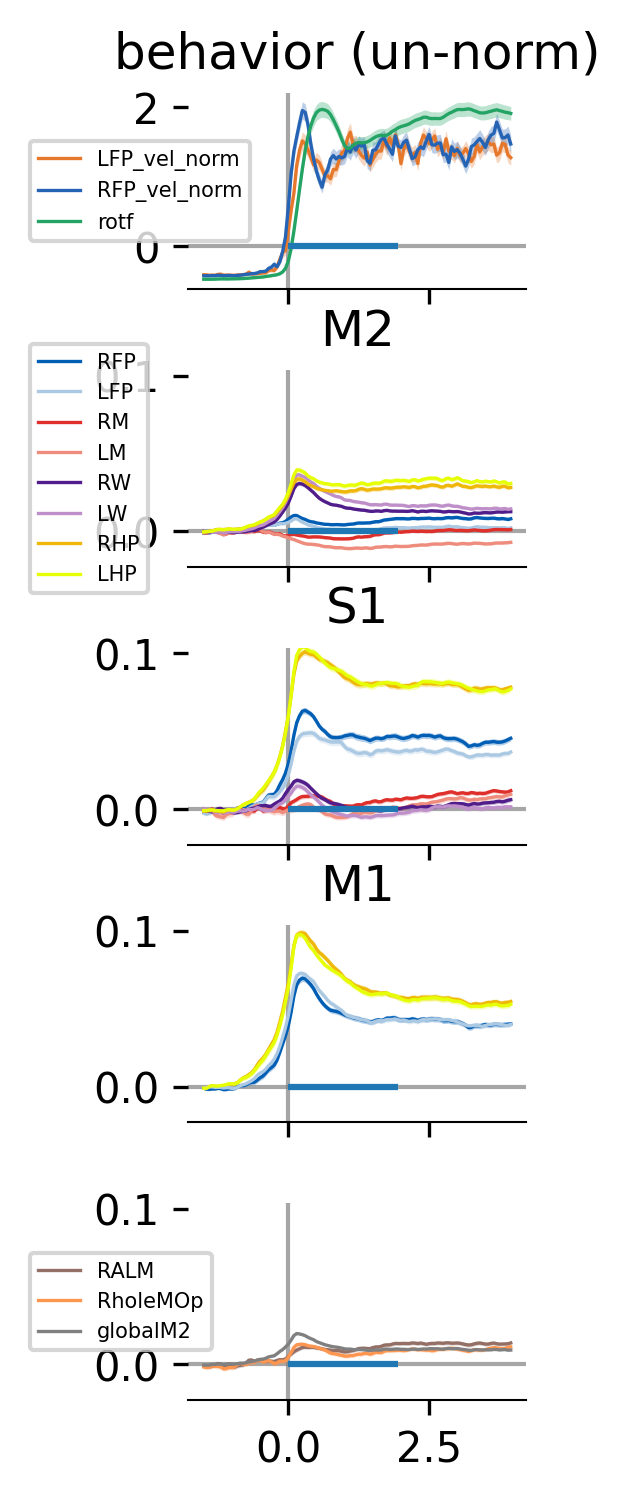

In [20]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;


# webcam image
# x_start = x_offset
# x_stop = x_start+8
# ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
x_start = x_offset
x_stop = x_start+5
# jrgeco snapshots for 'run'''''
# ax1 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# # colorbar for jrgeco snapshot
# x_start = x_stop
# x_stop = x_start+1
# ax991 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# time courses for behaviors
x_start = x_stop+1
x_stop = x_start+5
ax5 = fig.add_subplot(gs[y_offset-5:y_offset-2,x_start:x_stop])
# time courses for M2
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset-1:y_offset+2,x_start:x_stop])
# time courses for S1
x_start = x_start
x_stop = x_start+5
ax3 = fig.add_subplot(gs[y_offset+3:y_offset+6,x_start:x_stop])
# time courses for M1
x_start = x_start
x_stop = x_start+5
ax4 = fig.add_subplot(gs[y_offset+7:y_offset+10,x_start:x_stop])


x_start = x_start
x_stop = x_start+5
ax6 = fig.add_subplot(gs[y_offset+11:y_offset+14,x_start:x_stop])



# # webcam
# ax0.imshow(dict_webcam_img['lick'],cmap='gray')


T_total = time_range_to_cut.shape[0]
fs_here = 20
t_ax_trimmed = np.divide(range(-30,T_total-30),fs_here)
# time courses -M2
for i_bdp,bdp_name in enumerate(all_bdps_w_order):
    data_here = array_M2[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax2.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
# time courses -S1    
for i_bdp,bdp_name in enumerate(all_bdps_w_order):
    data_here = array_S1[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax3.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax3.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
# time courses -M1    
for i_bdp,bdp_name in enumerate(all_bdps_list_M1):
    data_here = array_M1[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax4.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax4.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
# time courses -behaviors
colors2=sns.color_palette()
for i_choice_behavior,behavior_here in enumerate(list_behavior):
    exec("data_here = {}".format(behavior_here))
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax5.plot(t_ax_trimmed,avg,label=behavior_here[2:],color=palatte_behavior_dict[behavior_here],linewidth=0.8)
    ax5.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_behavior_dict[behavior_here],alpha=0.3,lw=0)
    

# time courses - EXTRA
for i_bdp,bdp_name in enumerate([ 'RALM','RholeMOp','globalM2']):
    ind_in_list = all_bdps_nnls.index(bdp_name)
    data_here = array_all[ind_in_list,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax6.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax6.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    


# # ax2.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)
# # ax3.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)

# # jrgeco
# sbp1 = ax1.imshow(np.mean(np.mean(dict_full_jrgeco_dbsl_mice['cm229'][:,:,T_PRE_all_mice:T_PRE_all_mice+2,:],axis=2),axis=-1),cmap='icefire',vmin=-0.04,vmax=0.04)
# # add scatter plot
# for i_bdp, bdp_S1 in enumerate(list_choice_M2):
#     region_number = M1_ind_from_coherence[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker="D", s=6, c=palatte_dict[bdp_S1], zorder=2)
#     region_number = sensory_ind_here[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker='*', s=6, c=palatte_dict[bdp_S1], zorder=2)
#     ax1.scatter(node_coords_M2[bdp_S1][0], node_coords_M2[bdp_S1][1], s=3, c=palatte_dict[bdp_S1], zorder=2)

# #color bar
# cb = fig.colorbar(sbp1, cax=ax991,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
# cb.ax.tick_params(labelsize=7,length=2,color='black')
# cb.ax.yaxis.tick_right()       
# cb.outline.set_edgecolor('black')
# cb.outline.set_linewidth(0.5)
# tick_locator = ticker.MaxNLocator(nbins=3)
# cb.locator = tick_locator
# cb.update_ticks()
# ax991.set_aspect(100);ax991.set_anchor('W')


# ######
    
# exec("ax{}.set_xticks([]);ax{}.set_yticks([]);ax{}.set_xticks([]);ax{}.set_yticks([])".format(1,1,1,1))
# ax1.set_xlim([15,256]);ax1.set_ylim([256,15])
ax5.set_xticklabels([])
ax2.set_xticklabels([])
ax4.set_xticklabels([])
ax3.set_xticklabels([])

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,7):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
            
for i_ax in range(2,7):
    exec("ax{}.axvline(t_ax_trimmed[30],linewidth=1,color='gray',alpha=0.7,zorder=-999) ".format(i_ax)) 
    exec("ax{}.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999) ".format(i_ax)) 


for axis in ['top','right','left']:
    for i_ax in range(2,7):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
        
ax2.set_title('M2')
ax3.set_title('S1')
ax4.set_title('M1')
ax5.set_title('behavior (un-norm)')
ax2.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)
ax5.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)



ylim_here = [-0.02268334297536063, 0.10343791842258956]
ax2.set_ylim(ylim_here);ax3.set_ylim(ylim_here);ax4.set_ylim(ylim_here);ax6.set_ylim(ylim_here);

ax6.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)

ax3.hlines(y=0.0,xmin=t_ax_trimmed[ind_running[0]],xmax=t_ax_trimmed[ind_running[-1]])
ax4.hlines(y=0.0,xmin=t_ax_trimmed[ind_running[0]],xmax=t_ax_trimmed[ind_running[-1]])
ax5.hlines(y=0.0,xmin=t_ax_trimmed[ind_running[0]],xmax=t_ax_trimmed[ind_running[-1]])
ax2.hlines(y=0.0,xmin=t_ax_trimmed[ind_running[0]],xmax=t_ax_trimmed[ind_running[-1]])
ax6.hlines(y=0.0,xmin=t_ax_trimmed[ind_running[0]],xmax=t_ax_trimmed[ind_running[-1]])



plt.savefig('fig7-run-part1.svg',format='svg',dpi=300)

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/1416409652.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/1416409652.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/1416409652.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',


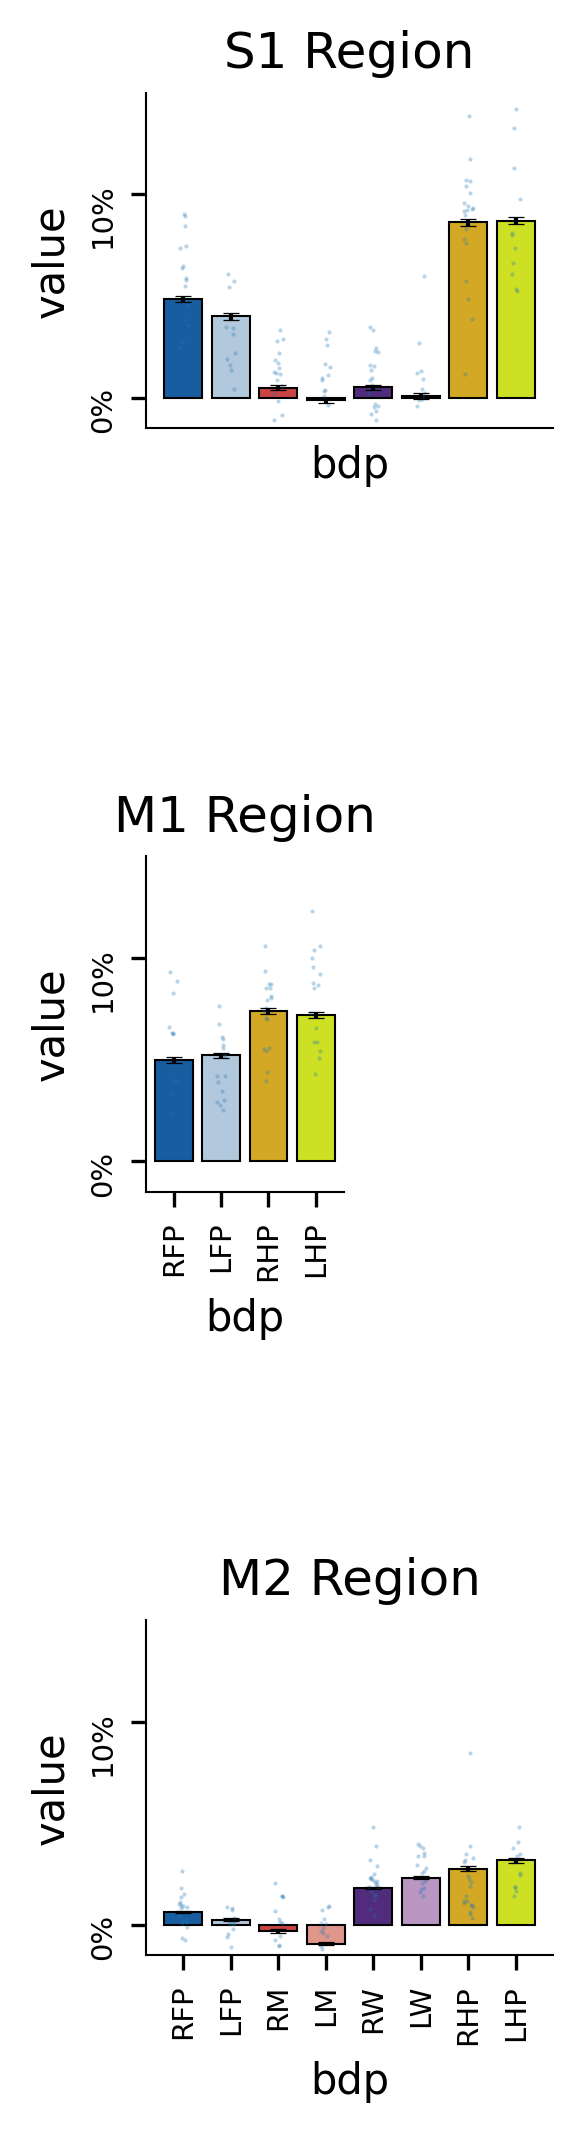

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from decimal import Decimal
from statannot import add_stat_annotation

plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

fmt = lambda x, pos: '{:.0%}'.format(x)

fig = plt.figure(figsize=(30, 30), dpi=300)
gs = GridSpec(100, 100)

y_offset = 20
x_offset = 20
x_start = x_offset

# Set widths to allow clean halving (6 for full, 3 for half)
width_full = 6
width_half = 3

# Define the 3 subplots stacked vertically
ax0 = fig.add_subplot(gs[y_offset : y_offset+5, x_start : x_start+width_full])        # S1
ax1 = fig.add_subplot(gs[y_offset+11 : y_offset+16, x_start : x_start+width_half])    # M1 (Half width)
ax2 = fig.add_subplot(gs[y_offset+22 : y_offset+27, x_start : x_start+width_full])    # M2

# Custom bodypart order
all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']
m1_display_order = ['RFP', 'LFP', 'RHP', 'LHP']

# Plot function updated for M1 and sub-sampling
def plot_with_stats(ax, region, order_list):
    df_region = df[df['region'] == region]
    
    if df_region.empty:
        print(f"WARNING: No data found for region '{region}'!")
        return
    
    import random
    random.seed(0)  # reproducible dot subsample across regenerations
    keep_ids = random.sample(range(len(df_region)), int(len(df_region)*0.25))
    df_region_down = df_region.iloc[keep_ids]
    
    # Plot bars with palette manually
    sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
                order=order_list,
                palette=palatte_dict, errorbar=None, zorder=1)

    # Overlay individual data points
    sns.stripplot(ax=ax, data=df_region_down.iloc[::3,:], x='bdp', y='value',
                  order=order_list, color='tab:blue',
                  size=1, jitter=True, zorder=3, alpha=0.3)

    # Bring bar borders to top layer
    for bar in ax.patches:
        bar.set_edgecolor('black')
        bar.set_linewidth(0.5)
        bar.set_zorder(2)
        
    # Manually draw error bars (mean ± SEM)
    for i, bdp in enumerate(order_list):
        values = df_region[df_region['bdp'] == bdp]['value']
        if not values.empty:
            mean = values.mean()
            sem = values.sem()
            ax.errorbar(i, mean, yerr=sem, fmt='none', ecolor='black',
                        capsize=2, capthick=0.3, linewidth=1, zorder=4)

    ax.set_title(f"{region} Region")

# Plot the 3 regions
plot_with_stats(ax0, "S1", all_bdps_w_order)
plot_with_stats(ax1, "M1", m1_display_order)
plot_with_stats(ax2, "M2", all_bdps_w_order)

# Y-axis formatting
ax0.set_ylim([-0.015, 0.15])       
ax1.set_ylim([-0.015, 0.15])  
ax2.set_ylim([-0.015, 0.15]) # Adjusted M2 to match the others

for ax in [ax0, ax1, ax2]:
    ax.set_yticks([0.00, 0.1])
    ax.set_yticks(ax.get_yticks(), ax.get_yticklabels(), rotation=90, fontsize=7)
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))

# X-axis formatting (S1 gets no ticks, M1 and M2 get rotated ticks)
ax0.set_xticks([])
ax1.set_xticks(ax1.get_xticks(), ax1.get_xticklabels(), rotation=90, fontsize=7)
ax2.set_xticks(ax2.get_xticks(), ax2.get_xticklabels(), rotation=90, fontsize=7)

# Spine formatting
for axis in ['top', 'right', 'left', 'bottom']:
    for ax in [ax0, ax1, ax2]:
        try:
            ax.spines[axis].set_linewidth(0.5)
        except:
            continue

for axis in ['top', 'right']:
    for ax in [ax0, ax1, ax2]:
        ax.spines[axis].set_linewidth(0)

plt.savefig('fig7-run-part4.svg', format='svg', dpi=300)
plt.show()

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/1148148894.py:101: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/1148148894.py:101: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',


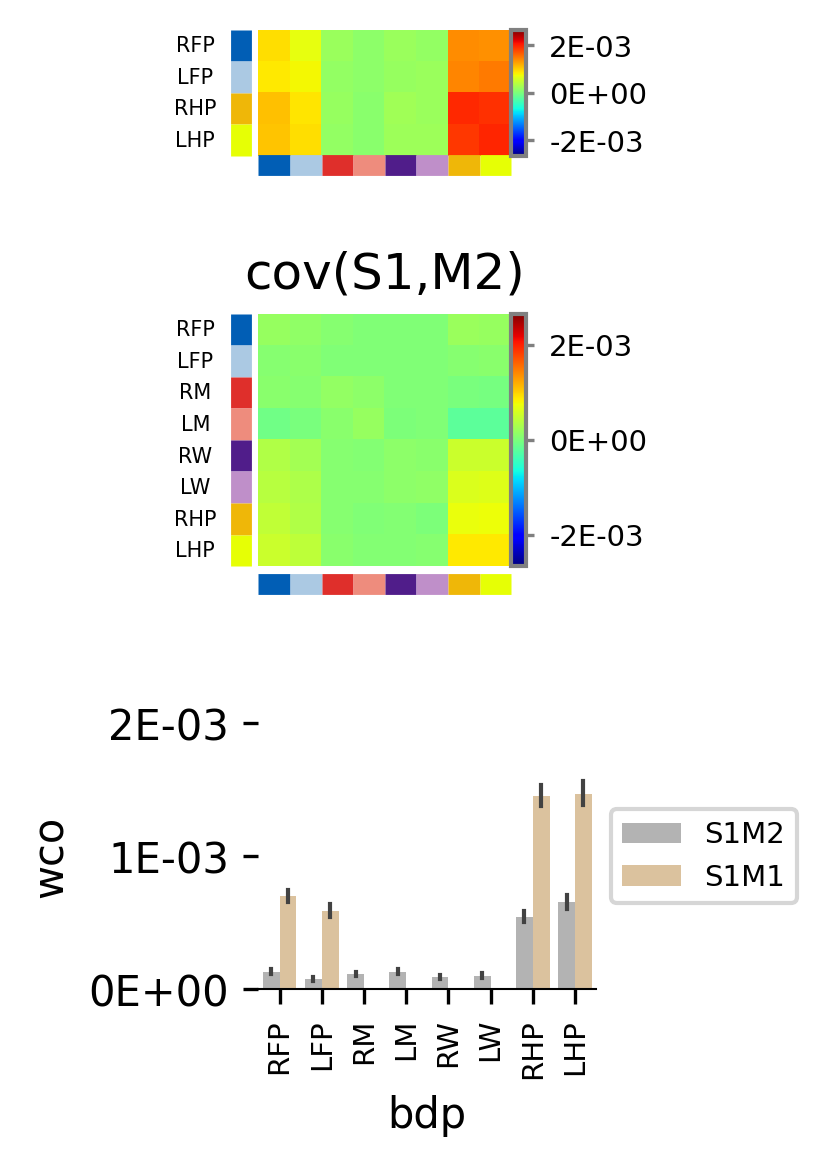

In [22]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from decimal import Decimal
fmt = lambda x, pos: '%.0E' % Decimal(x)

# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = y_offset
x_stop = x_start+4
ax0 = fig.add_subplot(gs[y_offset:y_offset+4,x_start:x_stop])
x_start = x_start
x_stop = x_start+4
ax1 = fig.add_subplot(gs[y_offset+5:y_offset+9,x_start:x_stop])
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset+11:y_offset+15,x_start:x_stop])

#=====

divnorm=colors.TwoSlopeNorm(vmin=-0.002, vcenter=0., vmax=0.002) 
i_ax=0
exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M1,0).T,cmap='jet',norm=divnorm)".format(i_ax,i_ax))
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=2,color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
start=-0.5;
for bdp in M1_bdps_w_order:
    stop = start + 1
    # ax0.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
    #         transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    ax0.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=5, clip_on=False,solid_capstyle='butt')
    # ax0.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    if i_ax == 0:
        ax0.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=5, va="top")
    start = stop
        
start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax0.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    start = stop
    
#####
divnorm=colors.TwoSlopeNorm(vmin=-0.002, vcenter=0., vmax=0.002) 
i_ax = 1

exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M2,0).T,cmap='jet',norm=divnorm)".format(i_ax,i_ax))

from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=2,color='gray')
cb.ax.yaxis.tick_right()
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)

exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))

start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax1.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    ax1.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=5, clip_on=False,solid_capstyle='butt')
    # ax1.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=5, va="top")
    start = stop
    
for i_ax in range(2):
    exec("ax{}.axis('off')".format(i_ax))
    
# ax0.set_title('cov(S1,M1)')
ax1.set_title('cov(S1,M2)')


sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',
            hue='S1M1_or_S1M2',
            palette=sns.color_palette("Set2")[::-1],
           errorbar=('ci', 95),errwidth=1)
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=7)

ax2.yaxis.set_major_formatter(FuncFormatter(fmt))
ax2.set_xticks(ax2.get_xticks(), ax2.get_xticklabels(), rotation=90,fontsize=7)



for axis in ['top','right','left','bottom']:
    for i_ax in range(2,3):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue

for axis in ['top','right','left']:
    for i_ax in range(2,3):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
        
ax2.set_ylim([0.0, 0.002])
plt.savefig('fig7-run-part2.svg',format='svg',dpi=300)

# brain maps

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3123615].


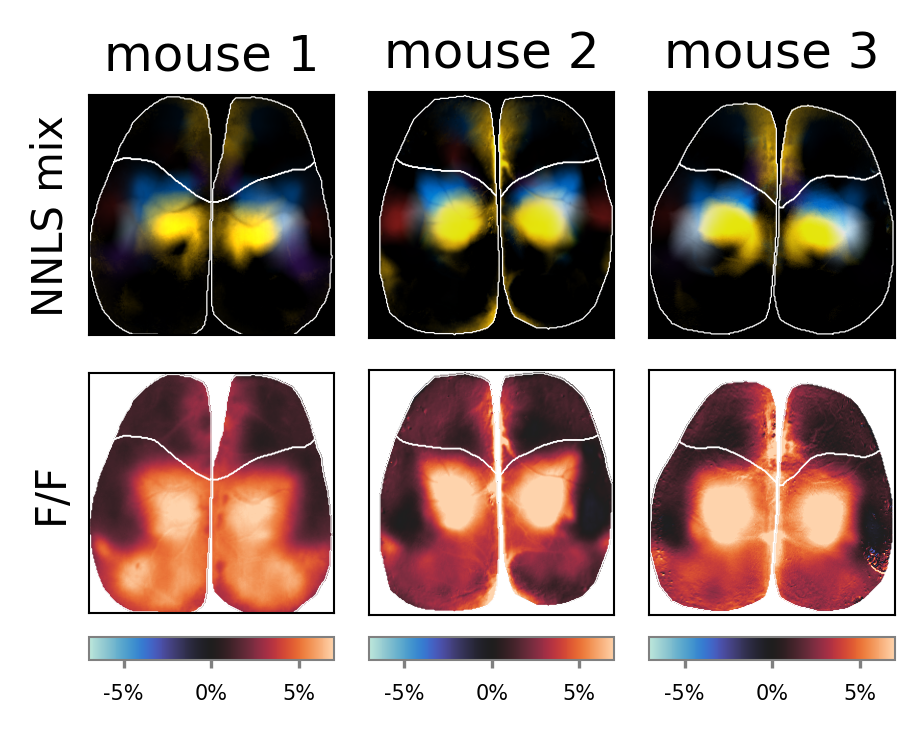

In [23]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;



x_start = x_offset
x_stop = x_start+4
y_start = y_offset
y_stop = y_start+4
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+4
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
    
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+1
for i_ax in range(3,6):
    exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
#===================
for i_mouse,mouse_id in enumerate(['cm229','cm125','cm126']):
    exec("ax{}.imshow(dict_blended_movie_per_mouse[mouse_id])".format(i_mouse))

    exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id],vmin=-0.07,vmax=0.07,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    contours = dict_contours_per_mouse[mouse_id]
    for contour in contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))
    for contour in contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))




ax3.set_xlim([21,256]);ax3.set_ylim([248,18]);ax0.set_xlim([21,256]);ax0.set_ylim([248,18])#cm229
# ax4.set_xlim([19,256]);ax4.set_ylim([237,0]);ax1.set_xlim([19,256]);ax1.set_ylim([237,0])#cm241
ax5.set_xlim([10,256]);ax5.set_ylim([256,10]);ax2.set_xlim([10,256]);ax2.set_ylim([256,10])#cm126



for i_ax in range(3,6):
    exec("cb = fig.colorbar(img{}, cax=ax99{},fraction=0.2,orientation='horizontal',format=FuncFormatter(fmt));".format(i_ax,i_ax))
    cb.ax.tick_params(labelsize=5,length=2,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(0.5)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    exec("ax99{}.set_aspect(0.013)".format(i_ax))
    exec("ax99{}.set_anchor('N')".format(i_ax))


for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue 
            
ax0.set_title('mouse 1');ax1.set_title('mouse 2');ax2.set_title('mouse 3')

ax3.set_ylabel('F/F');#ax4.set_title('F/F');ax5.set_title('F/F')
ax0.set_ylabel('NNLS mix');

plt.subplots_adjust(wspace=1)
plt.savefig('fig7-run-part3.svg',format='svg',dpi=300)


# INTEGRATED

In [24]:
for mouse_id in ['cm229','cm126','cm128']:
    dict_all = load_pickle(fetch_path_data+'dict_all_integrated_'+mouse_id)
    dict_all_data = dict_all['dict_all_data']
    # print(dict_all_data['dict_behaviors'].keys())
    
    dict_all_data['dict_behaviors']={key.replace('norm_','').replace('_norm',''):v for key,v in dict_all_data['dict_behaviors'].items()}
    print(dict_all_data['dict_behaviors'].keys())  
        
        

dict_keys(['M_RFP_vel', 'M_LFP_vel', 'M_is_groom', 'M_rotf'])
dict_keys(['M_LFP_vel', 'M_RFP_vel', 'M_rotf', 'M_is_groom'])
dict_keys(['M_LFP_vel', 'M_RFP_vel', 'M_rotf', 'M_is_groom'])


In [25]:
t_total = 50
array_S1,array_M1,array_M2,array_all = np.empty((8,t_total,0)),np.empty((4,t_total,0)),np.empty((8,t_total,0)),np.empty((42,t_total,0))
list_behavior = ['M_is_groom', 'M_LFP_vel', 'M_RFP_vel', 'M_rotf']
M_is_groom, M_LFP_vel, M_RFP_vel, M_rotf = np.empty((t_total,0)),np.empty((t_total,0)),np.empty((t_total,0)),np.empty((t_total,0))
array_cov_S1M1,array_cov_S1M2,array_cov_M1M2=np.empty((0,8,4)),np.empty((0,8,8)),np.empty((0,8,4))
wco_pot=pd.DataFrame() 

dict_contours_per_mouse = {}
dict_blended_movie_per_mouse = {}
dict_AVG_full_jrgeco_2_save_per_mouse = {}

amplitude_data_dict = {}
for mouse_id in ['cm229','cm126','cm128']:
    dict_here = load_pickle(figure_config_root+'M2-S1M1_area_segment_'+mouse_id)
    dict_contours_per_mouse[mouse_id] = dict_here['contours']
    dict_all = load_pickle(fetch_path_data+'dict_all_integrated_'+mouse_id)
    dict_all_stats = dict_all['dict_all_stats']
    dict_all_data = dict_all['dict_all_data']
    
    all_bdps_w_order = dict_all_stats['all_bdps_w_order']
    T_PRE_rise = dict_all_data['T_PRE_rise']
    T_PRE_lick = dict_all_data['T_PRE_lick']
    time_range_to_cut = np.arange(8,58)

    array_S1_this = dict_all_data['array_S1'][:,time_range_to_cut,:]
    array_M1_this = dict_all_data['array_M1'][:,time_range_to_cut,:]
    array_M2_this = dict_all_data['array_M2'][:,time_range_to_cut,:]
    array_S1 = np.append(array_S1,array_S1_this,axis=2)
    array_M1 = np.append(array_M1,array_M1_this,axis=2)
    array_M2 = np.append(array_M2,array_M2_this,axis=2)
    array_all = np.append(array_all,dict_all_data['H_nnls_bouts'][:,time_range_to_cut,:],axis=2)

    ind_integrated = range(8,8+30)
    # FIX: use this mouse's own bouts only -- see cell 5's note.
    amplitude_data_dict[mouse_id]= {'S1': np.mean(array_S1_this[:,ind_integrated,:],axis=1),
                   'M2': np.mean(array_M2_this[:,ind_integrated,:],axis=1),
                                   'M1': np.mean(array_M1_this[:,ind_integrated,:],axis=1)}


    dict_all_data['dict_behaviors']={key.replace('norm_','').replace('_norm',''):v for key,v in dict_all_data['dict_behaviors'].items()}
    print(dict_all_data['dict_behaviors'].keys()) 
    for behavior in list_behavior:
        exec("{} = np.append({},dict_all_data['dict_behaviors'][behavior][time_range_to_cut,:],axis=1)".format(behavior,behavior))


    for cov_array_type in ['S1M2']:
        exec("array_cov_{} = np.append(array_cov_{},dict_all_stats['array_cov_'+cov_array_type],axis=0)".format(cov_array_type,cov_array_type))
        # Assemble coherence STATS pot
        for i_bdp, bdp in enumerate(all_bdps_w_order):  
            diff_temp=pd.DataFrame(columns=['wco','mouse','bdp','S1M1_or_S1M2'])
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,i_bdp,i_bdp]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])
            
    for cov_array_type in ['S1M1']:
        ss = dict_all_stats['array_cov_'+cov_array_type].shape
        cov_S1M1 = np.zeros((ss[0],8,4));cov_S1M1[:]=np.nan
        indices_S1 = range(len(all_bdps_w_order))
        indices_M1 = [all_bdps_list_M1.index(item) for item in M1_bdps_w_order]
        cov_S1M1[np.ix_(range(ss[0]),range(8), range(4))] = dict_all_stats['array_cov_'+cov_array_type][np.ix_(range(ss[0]),indices_S1, indices_M1)]           
        
        exec("array_cov_{} = np.append(array_cov_{},cov_S1M1,axis=0)".format(cov_array_type,cov_array_type))
        for i_bdp_M1, bdp_M1 in enumerate(all_bdps_list_M1):
            ind_in_all_bdps_list = all_bdps_w_order.index(bdp_M1)
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,ind_in_all_bdps_list,i_bdp_M1]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp_M1
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])             
        
    for cov_array_type in ['M1M2']:
        exec("array_cov_{} = np.append(array_cov_{},dict_all_stats['array_cov_'+cov_array_type],axis=0)".format(cov_array_type,cov_array_type))
        for i_bdp_M1, bdp_M1 in enumerate(all_bdps_list_M1):
            ind_in_all_bdps_list = all_bdps_w_order.index(bdp_M1)
            diff_temp['wco'] = dict_all_stats['array_cov_'+cov_array_type][:,ind_in_all_bdps_list,i_bdp_M1]
            diff_temp['S1M1_or_S1M2'] = cov_array_type
            diff_temp['bdp'] = bdp_M1
            diff_temp['mouse'] = mouse_id
            wco_pot = pd.concat([wco_pot, diff_temp])  
        
    if mouse_id == 'cm126':
        rise_scaling_factor = 2
        lick_scaling_factor = 1.2
        rise_time_frame = range(T_PRE_rise-3,T_PRE_lick-4)
    elif mouse_id == 'cm128':
        rise_scaling_factor = 1.4
        lick_scaling_factor = 1.2
        rise_time_frame = range(T_PRE_rise+1,T_PRE_lick-3)
    elif mouse_id == 'cm229':
        rise_scaling_factor = 2
        lick_scaling_factor = 1.2
        rise_time_frame = range(T_PRE_rise,T_PRE_lick-3)
        
    dict_blended_movie_per_mouse[mouse_id] = {}
    dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id] = {}
    
    
    
    dict_blended_movie_per_mouse[mouse_id]['rise'] = np.mean(
        dict_all_data['blended_movie_2_save'][:,:,:,rise_time_frame]*rise_scaling_factor,-1)
    dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['rise'] = np.mean(
        dict_all_data['AVG_full_jrgeco_2_save'][:,:,rise_time_frame],-1)  
    
    dict_blended_movie_per_mouse[mouse_id]['lick'] = np.mean(
        dict_all_data['blended_movie_2_save'][:,:,:,T_PRE_lick:]*lick_scaling_factor,-1)
    dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['lick'] = np.mean(
        dict_all_data['AVG_full_jrgeco_2_save'][:,:,T_PRE_lick:],-1)  
    
    print(mouse_id,': ',dict_all_data['array_S1'].shape[-1])


dict_keys(['M_RFP_vel', 'M_LFP_vel', 'M_is_groom', 'M_rotf'])
cm229 :  16
dict_keys(['M_LFP_vel', 'M_RFP_vel', 'M_rotf', 'M_is_groom'])
cm126 :  15
dict_keys(['M_LFP_vel', 'M_RFP_vel', 'M_rotf', 'M_is_groom'])
cm128 :  7


In [26]:
rows = []
all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']

# Use this ONLY for unpacking the matrix correctly!
m1_raw_data_order = ['RFP', 'RHP', 'LFP', 'LHP'] 

for mouse_id, region_dict in amplitude_data_dict.items():
    for region_name, matrix in region_dict.items():
        if region_name == 'M1':
            current_bdp_list = m1_raw_data_order
        else:
            current_bdp_list = all_bdps_w_order
            
        for bdp_idx, bdp in enumerate(current_bdp_list):
            for bout_idx, value in enumerate(matrix[bdp_idx]):
                rows.append({
                    'mouse_id': mouse_id, 'region': region_name,
                    'bdp': bdp, 'bout': bout_idx, 'value': value
                })

df = pd.DataFrame(rows)


In [27]:
df['movement_type'] = 'integrated'
GRAND_DF = pd.concat([GRAND_DF, df])

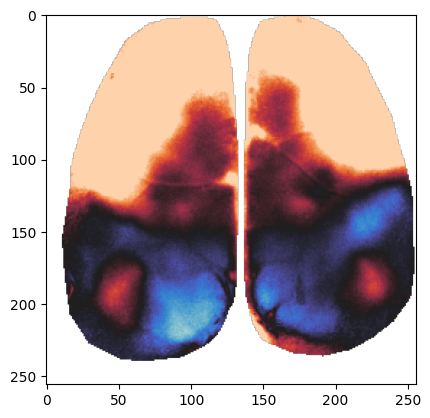

In [28]:
# data_here=np.mean(dict_all_data['AVG_full_jrgeco_2_save'][:,:,T_PRE_rise-3:T_PRE_lick]*2,-1)
# plt.imshow(data_here,vmin=-0.03,vmax=0.03,cmap='icefire')
data_here=np.mean(dict_all_data['AVG_full_jrgeco_2_save'][:,:,T_PRE_lick:T_PRE_lick+20]*2,-1)
plt.imshow(data_here,vmin=-0.06,vmax=0.06,cmap='icefire')

In [29]:
wco_pot  = wco_pot[np.logical_or(wco_pot['S1M1_or_S1M2']=='S1M2',
                                           wco_pot['S1M1_or_S1M2']=='S1M1')]

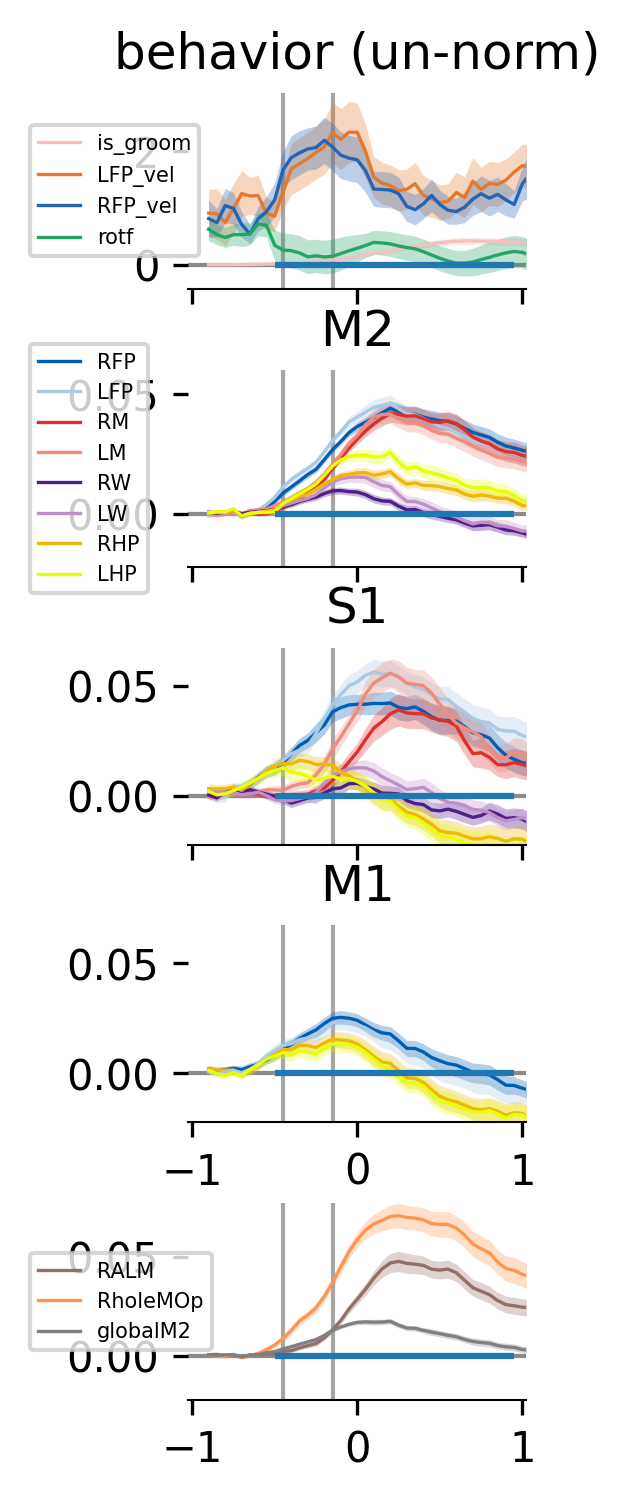

In [30]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;


# webcam image
# x_start = x_offset
# x_stop = x_start+8
# ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
x_start = x_offset
x_stop = x_start+5
# jrgeco snapshots for 'run'''''
# ax1 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# # colorbar for jrgeco snapshot
# x_start = x_stop
# x_stop = x_start+1
# ax991 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# time courses for behaviors
x_start = x_stop+1
x_stop = x_start+5
ax5 = fig.add_subplot(gs[y_offset-5:y_offset-2,x_start:x_stop])
# time courses for M2
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset-1:y_offset+2,x_start:x_stop])
# time courses for S1
x_start = x_start
x_stop = x_start+5
ax3 = fig.add_subplot(gs[y_offset+3:y_offset+6,x_start:x_stop])
# time courses for M1
x_start = x_start
x_stop = x_start+5
ax4 = fig.add_subplot(gs[y_offset+7:y_offset+10,x_start:x_stop])

# time courses for EXTRA
x_start = x_start
x_stop = x_start+5
ax6 = fig.add_subplot(gs[y_offset+11:y_offset+14,x_start:x_stop])



# # webcam
# ax0.imshow(dict_webcam_img['lick'],cmap='gray')


T_total = time_range_to_cut.shape[0]
fs_here = 20
t_ax_trimmed = np.divide(range(-18,T_total-18),fs_here)
# time courses -M2
for i_bdp,bdp_name in enumerate(all_bdps_w_order):
    data_here = array_M2[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax2.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
# time courses -S1    
for i_bdp,bdp_name in enumerate(all_bdps_w_order):
    data_here = array_S1[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax3.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax3.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
# time courses -M1    
for i_bdp,bdp_name in enumerate(all_bdps_list_M1):
    data_here = array_M1[i_bdp,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax4.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax4.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
# time courses -behaviors
colors2=sns.color_palette()
for i_choice_behavior,behavior_here in enumerate(list_behavior):
    exec("data_here = {}".format(behavior_here))
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax5.plot(t_ax_trimmed,avg,label=behavior_here[2:],color=palatte_behavior_dict[behavior_here],linewidth=0.8)
    ax5.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_behavior_dict[behavior_here],alpha=0.3,lw=0)
    
for i_bdp,bdp_name in enumerate([ 'RALM','RholeMOp','globalM2']):
    ind_in_list = all_bdps_nnls.index(bdp_name)
    data_here = array_all[ind_in_list,:,:]
    avg = np.nanmean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax6.plot(t_ax_trimmed,avg,label=bdp_name,color=palatte_dict[bdp_name],linewidth=0.8)
    ax6.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp_name],alpha=0.3,lw=0)
    
    

# # ax2.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)
# # ax3.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)

# # jrgeco
# sbp1 = ax1.imshow(np.mean(np.mean(dict_full_jrgeco_dbsl_mice['cm229'][:,:,T_PRE_all_mice:T_PRE_all_mice+2,:],axis=2),axis=-1),cmap='icefire',vmin=-0.04,vmax=0.04)
# # add scatter plot
# for i_bdp, bdp_S1 in enumerate(list_choice_M2):
#     region_number = M1_ind_from_coherence[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker="D", s=6, c=palatte_dict[bdp_S1], zorder=2)
#     region_number = sensory_ind_here[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker='*', s=6, c=palatte_dict[bdp_S1], zorder=2)
#     ax1.scatter(node_coords_M2[bdp_S1][0], node_coords_M2[bdp_S1][1], s=3, c=palatte_dict[bdp_S1], zorder=2)

# #color bar
# cb = fig.colorbar(sbp1, cax=ax991,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
# cb.ax.tick_params(labelsize=7,length=2,color='black')
# cb.ax.yaxis.tick_right()       
# cb.outline.set_edgecolor('black')
# cb.outline.set_linewidth(0.5)
# tick_locator = ticker.MaxNLocator(nbins=3)
# cb.locator = tick_locator
# cb.update_ticks()
# ax991.set_aspect(100);ax991.set_anchor('W')


# ######
    
# exec("ax{}.set_xticks([]);ax{}.set_yticks([]);ax{}.set_xticks([]);ax{}.set_yticks([])".format(1,1,1,1))
# ax1.set_xlim([15,256]);ax1.set_ylim([256,15])
ax5.set_xticklabels([])
ax2.set_xticklabels([])
ax3.set_xticklabels([])

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,7):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
            
for i_ax in range(2,7):
    exec("ax{}.axvline(t_ax_trimmed[T_PRE_rise-8],linewidth=1,color='gray',alpha=0.7,zorder=-999) ".format(i_ax)) 
    exec("ax{}.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999) ".format(i_ax)) 
for i_ax in range(2,7):
    exec("ax{}.axvline(t_ax_trimmed[T_PRE_lick-8],linewidth=1,color='gray',alpha=0.7,zorder=-999) ".format(i_ax)) 
    exec("ax{}.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999) ".format(i_ax)) 

for axis in ['top','right','left']:
    for i_ax in range(2,7):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
        
ax2.set_title('M2')
ax3.set_title('S1')
ax4.set_title('M1')
ax5.set_title('behavior (un-norm)')
ax2.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)
ax5.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)

ax2.set_xlim([-1.0225, 1.0225])
ax3.set_xlim([-1.0225, 1.0225])
ax4.set_xlim([-1.0225, 1.0225])
ax5.set_xlim([-1.0225, 1.0225])
ax6.set_xlim([-1.0225, 1.0225])


ax2.set_ylim([-0.022251286970597914, 0.06019783984669744])
ax3.set_ylim([-0.022251286970597914, 0.06719783984669744])
ax4.set_ylim([-0.022251286970597914, 0.06719783984669744])
ax6.set_ylim([-0.022251286970597914, 0.07719783984669744])

ax3.hlines(y=0.0,xmin=t_ax_trimmed[ind_integrated[0]],xmax=t_ax_trimmed[ind_integrated[-1]])
ax4.hlines(y=0.0,xmin=t_ax_trimmed[ind_integrated[0]],xmax=t_ax_trimmed[ind_integrated[-1]])
ax5.hlines(y=0.0,xmin=t_ax_trimmed[ind_integrated[0]],xmax=t_ax_trimmed[ind_integrated[-1]])
ax2.hlines(y=0.0,xmin=t_ax_trimmed[ind_integrated[0]],xmax=t_ax_trimmed[ind_integrated[-1]])
ax6.hlines(y=0.0,xmin=t_ax_trimmed[ind_integrated[0]],xmax=t_ax_trimmed[ind_integrated[-1]])


ax6.legend(loc='center left', bbox_to_anchor=(-0.5, 0.5),fontsize=5)

plt.savefig('fig7-integrated-part1.svg',format='svg',dpi=300)

In [31]:
# plt.style.use('default')
# from matplotlib.gridspec import GridSpec
# gs = GridSpec(100,100)
# from matplotlib import ticker
# from matplotlib.ticker import FuncFormatter
# from decimal import Decimal
# from statannot import add_stat_annotation

# fmt = lambda x, pos: '{:.0%}'.format(x)

# # with plt.style.context(spstyle.get_style('nature')):
# plt.rcParams['svg.fonttype'] = 'none'
# fig = plt.figure(figsize=(30,30),dpi=300)

# y_offset = 20;x_offset=20;


# x_start = y_offset
# x_stop = x_start+5
# ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# ax1 = fig.add_subplot(gs[y_offset+11:y_offset+11+5,x_start:x_stop])



# # Custom bodypart order
# all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']

# # Define statistical comparison pairs
# box_pairs_S1 = [('RM', 'RFP'), ('RM', 'RHP'), ('RM', 'RW'),
#                 ('LM', 'LFP'), ('LM', 'LHP'), ('LM', 'LW')]
# box_pairs_M2 = [('RM', 'RFP'), ('RM', 'RHP'), ('RM', 'RW'),
#                 ('LM', 'LFP'), ('LM', 'LHP'), ('LM', 'LW')]

# # Set up the figure
# # Plot function
# def plot_with_stats(ax, region, pairs):
#     df_region = df[df['region'] == region]

#     # Plot bars with palette manually
#     sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
#                 order=all_bdps_w_order,
#                 palette=palatte_dict,errorbar=None, zorder=1)

#     # Overlay individual data points
#     sns.stripplot(ax=ax, data=df_region, x='bdp', y='value',
#                   order=all_bdps_w_order, color='tab:blue',
#                   size=1, jitter=True, dodge=True, zorder=3,alpha=0.3)

#     # Bring bar borders to top layer
#     for bar in ax.patches:
#         bar.set_edgecolor('black')
#         bar.set_linewidth(0.5)
#         bar.set_zorder(2)
        
#     # Manually draw error bars (mean ± SEM)
#     for i, bdp in enumerate(all_bdps_w_order):
#         values = df_region[df_region['bdp'] == bdp]['value']
#         mean = values.mean()
#         sem = values.sem()
#         ax.errorbar(i, mean, yerr=sem, fmt='none', ecolor='black',
#                     capsize=2, capthick=0.3, linewidth=1, zorder=4)

        
#     # Add stat annotations
#     # add_stat_annotation(ax, data=df_region, x="bdp", y="value",
#     #                     order=all_bdps_w_order, box_pairs=pairs,
#     #                     test='Wilcoxon', text_format='star', loc='outside',
#     #                     verbose=1, line_height=0.0, text_offset=-0.4,
#     #                     fontsize=5, linewidth=0.7, color='#454545',
#     #                     line_offset=0.001, line_offset_to_box=0.2)
    
#     ax.set_title(f"{region} Region")

# # Plot both regions
# plot_with_stats(ax0, "S1", box_pairs_S1)
# plot_with_stats(ax1, "M2", box_pairs_M2)

# ax0.set_ylim([-0.02, 0.06])       
# ax1.set_ylim([-0.02, 0.055])
# ax0.set_yticks([0.00, 0.04])
# ax1.set_yticks([0.00, 0.04])
# ax0.set_yticks(ax0.get_yticks(), ax0.get_yticklabels(), rotation=90,fontsize=7)
# ax1.set_yticks(ax1.get_yticks(), ax1.get_yticklabels(), rotation=90,fontsize=7)
# ax0.yaxis.set_major_formatter(FuncFormatter(fmt))
# ax1.yaxis.set_major_formatter(FuncFormatter(fmt))
# ax0.set_xticks([])
# ax1.set_xticks(ax1.get_xticks(), ax1.get_xticklabels(), rotation=90,fontsize=7)


# for axis in ['top','right','left','bottom']:
#     for i_ax in range(3):
#         try:
#             exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
#         except:
#             continue

# for axis in ['top','right']:
#     for i_ax in range(3):
#         exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))



# plt.savefig('fig7-integrated-part4.svg',format='svg',dpi=300)

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/3560653335.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/3560653335.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/3560653335.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_region, x='bdp', y='value',


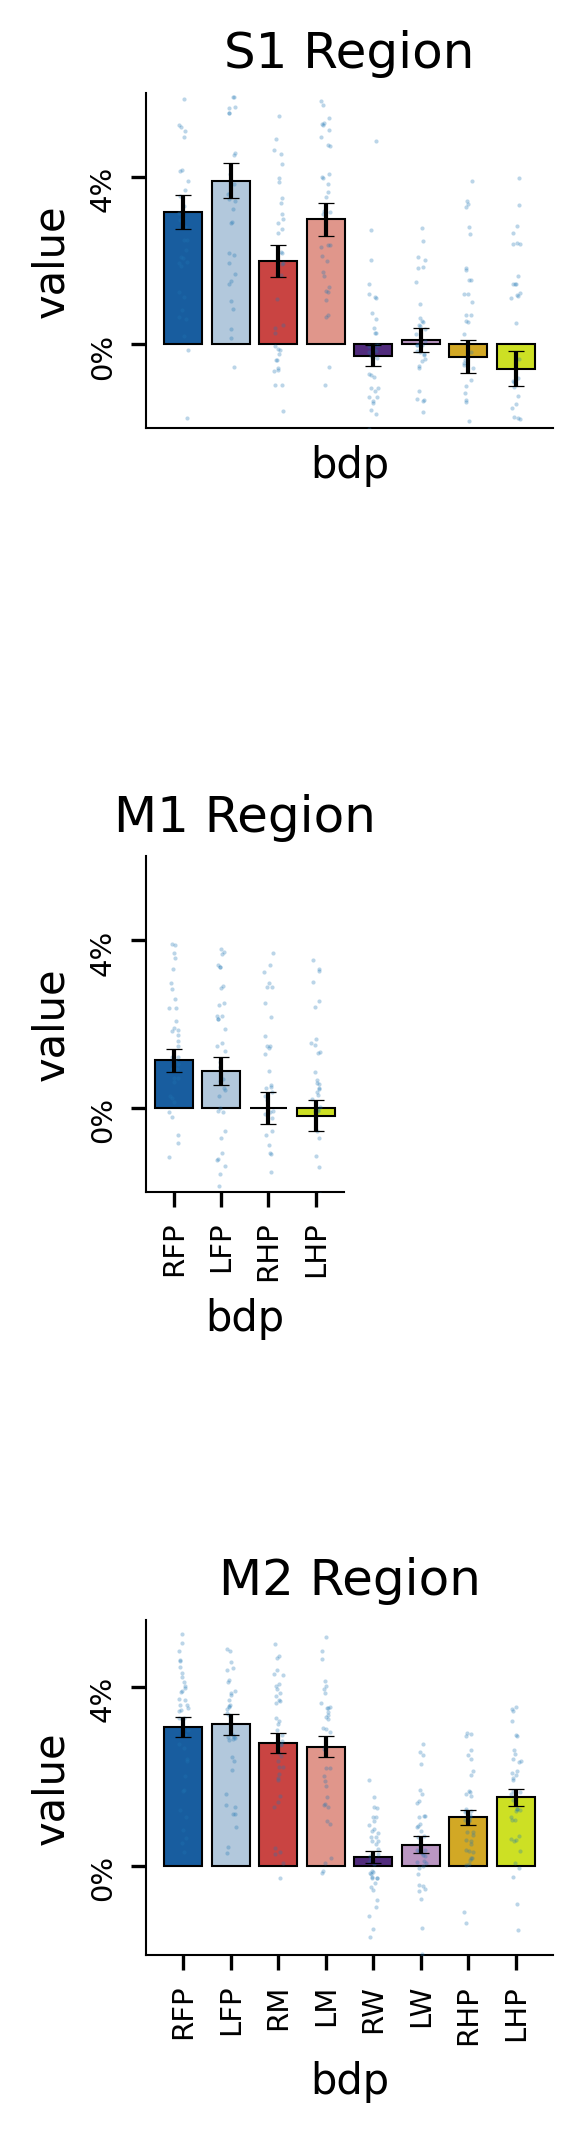

In [32]:


plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

fmt = lambda x, pos: '{:.0%}'.format(x)

fig = plt.figure(figsize=(30, 30), dpi=300)
gs = GridSpec(100, 100)

y_offset = 20
x_offset = 20
x_start = x_offset

# Set widths to allow clean halving (6 for full, 3 for half)
width_full = 6
width_half = 3

# Define the 3 subplots stacked vertically
ax0 = fig.add_subplot(gs[y_offset : y_offset+5, x_start : x_start+width_full])        # S1
ax1 = fig.add_subplot(gs[y_offset+11 : y_offset+16, x_start : x_start+width_half])    # M1 (Half width)
ax2 = fig.add_subplot(gs[y_offset+22 : y_offset+27, x_start : x_start+width_full])    # M2

# Custom bodypart orders
all_bdps_w_order = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']
m1_display_order = ['RFP', 'LFP', 'RHP', 'LHP'] # Display order for M1

# Plot function 
def plot_with_stats(ax, region, order_list):
    df_region = df[df['region'] == region]
    
    # Quick safety check
    if df_region.empty:
        print(f"WARNING: No data found for region '{region}'!")
        return

    # Plot bars with palette manually
    sns.barplot(ax=ax, data=df_region, x='bdp', y='value',
                order=order_list,
                palette=palatte_dict, errorbar=None, zorder=1)

    # Overlay individual data points
    # ---> dodge=True is removed
    sns.stripplot(ax=ax, data=df_region, x='bdp', y='value',
                  order=order_list, color='tab:blue',
                  size=1, jitter=True, zorder=3, alpha=0.3)

    # Bring bar borders to top layer
    for bar in ax.patches:
        bar.set_edgecolor('black')
        bar.set_linewidth(0.5)
        bar.set_zorder(2)
        
    # Manually draw error bars (mean ± SEM)
    for i, bdp in enumerate(order_list):
        values = df_region[df_region['bdp'] == bdp]['value']
        if not values.empty:
            mean = values.mean()
            sem = values.sem()
            ax.errorbar(i, mean, yerr=sem, fmt='none', ecolor='black',
                        capsize=2, capthick=0.3, linewidth=1, zorder=4)

    ax.set_title(f"{region} Region")

# Plot the 3 regions using their respective display orders
plot_with_stats(ax0, "S1", all_bdps_w_order)
plot_with_stats(ax1, "M1", m1_display_order) 
plot_with_stats(ax2, "M2", all_bdps_w_order)

# Y-axis formatting
ax0.set_ylim([-0.02, 0.06])       
ax1.set_ylim([-0.02, 0.06])  # Matched M1 to S1 limits
ax2.set_ylim([-0.02, 0.055])

for ax in [ax0, ax1, ax2]:
    ax.set_yticks([0.00, 0.04])
    ax.set_yticks(ax.get_yticks(), ax.get_yticklabels(), rotation=90, fontsize=7)
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))

# X-axis formatting (S1 gets no ticks, M1 and M2 get rotated ticks)
ax0.set_xticks([])
ax1.set_xticks(ax1.get_xticks(), ax1.get_xticklabels(), rotation=90, fontsize=7)
ax2.set_xticks(ax2.get_xticks(), ax2.get_xticklabels(), rotation=90, fontsize=7)

# Spine formatting
for axis in ['top', 'right', 'left', 'bottom']:
    for ax in [ax0, ax1, ax2]:
        try:
            ax.spines[axis].set_linewidth(0.5)
        except:
            continue

for axis in ['top', 'right']:
    for ax in [ax0, ax1, ax2]:
        ax.spines[axis].set_linewidth(0)

plt.savefig('fig7-integrated-part4.svg', format='svg', dpi=300)
plt.show()

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/4210862862.py:100: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/4210862862.py:100: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',


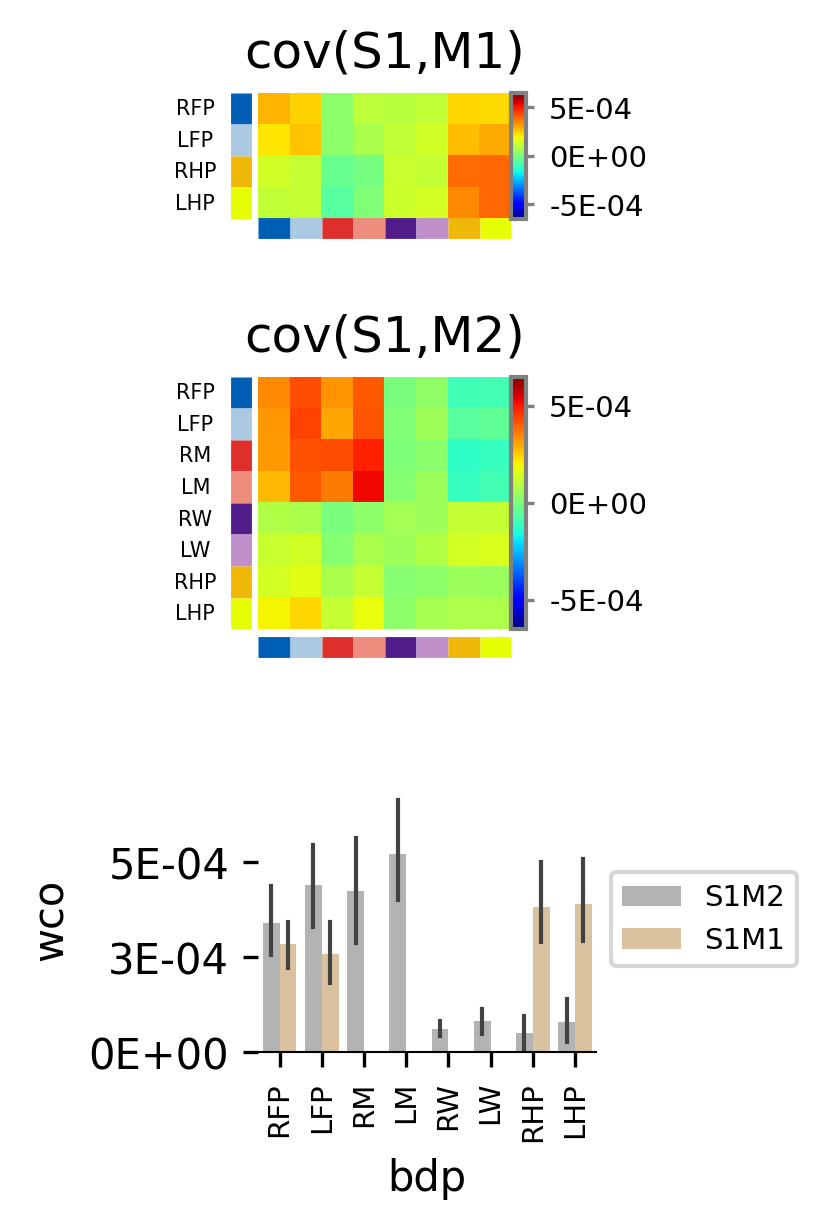

In [33]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from decimal import Decimal
fmt = lambda x, pos: '%.0E' % Decimal(x)

# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = y_offset
x_stop = x_start+4
ax0 = fig.add_subplot(gs[y_offset:y_offset+4,x_start:x_stop])
x_start = x_start
x_stop = x_start+4
ax1 = fig.add_subplot(gs[y_offset+5:y_offset+9,x_start:x_stop])
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset+11:y_offset+15,x_start:x_stop])

#=====

divnorm=colors.TwoSlopeNorm(vmin=-0.00065, vcenter=0., vmax=0.00065) 
i_ax=0
exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M1,0).T,cmap='jet',norm=divnorm)".format(i_ax,i_ax))
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=2,color='gray')
cb.ax.yaxis.tick_right()
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
start=-0.5;
for bdp in M1_bdps_w_order:
    stop = start + 1
    ax0.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=5, clip_on=False,solid_capstyle='butt')
    # ax0.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    if i_ax == 0:
        ax0.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=5, va="top")
    start = stop
        
start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax0.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    start = stop
    
    
#####
divnorm=colors.TwoSlopeNorm(vmin=-0.00065, vcenter=0., vmax=0.00065) 
i_ax = 1

exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M2,0).T,cmap='jet',norm=divnorm)".format(i_ax,i_ax))

from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=2,color='gray')
cb.ax.yaxis.tick_right()
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)

exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))

start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax1.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=5, clip_on=False,solid_capstyle='butt')
    ax1.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=5, clip_on=False,solid_capstyle='butt')
    # ax1.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=5, va="top")
    start = stop
    
for i_ax in range(2):
    exec("ax{}.axis('off')".format(i_ax))
    
ax0.set_title('cov(S1,M1)')
ax1.set_title('cov(S1,M2)')


sns.barplot(ax=ax2,data=wco_pot, x='bdp', y='wco',
            hue='S1M1_or_S1M2',
            palette=sns.color_palette("Set2")[::-1],
           errorbar=('ci', 95),errwidth=1)
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=7)

ax2.yaxis.set_major_formatter(FuncFormatter(fmt))
ax2.set_xticks(ax2.get_xticks(), ax2.get_xticklabels(), rotation=90,fontsize=7)



for axis in ['top','right','left','bottom']:
    for i_ax in range(2,3):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue

for axis in ['top','right','left']:
    for i_ax in range(2,3):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
   
ax2.set_ylim([0.0, 0.0007])
plt.savefig('fig7-integrated-part2.svg',format='svg',dpi=300)

# brain maps

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.6132973].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3854675].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3779683].


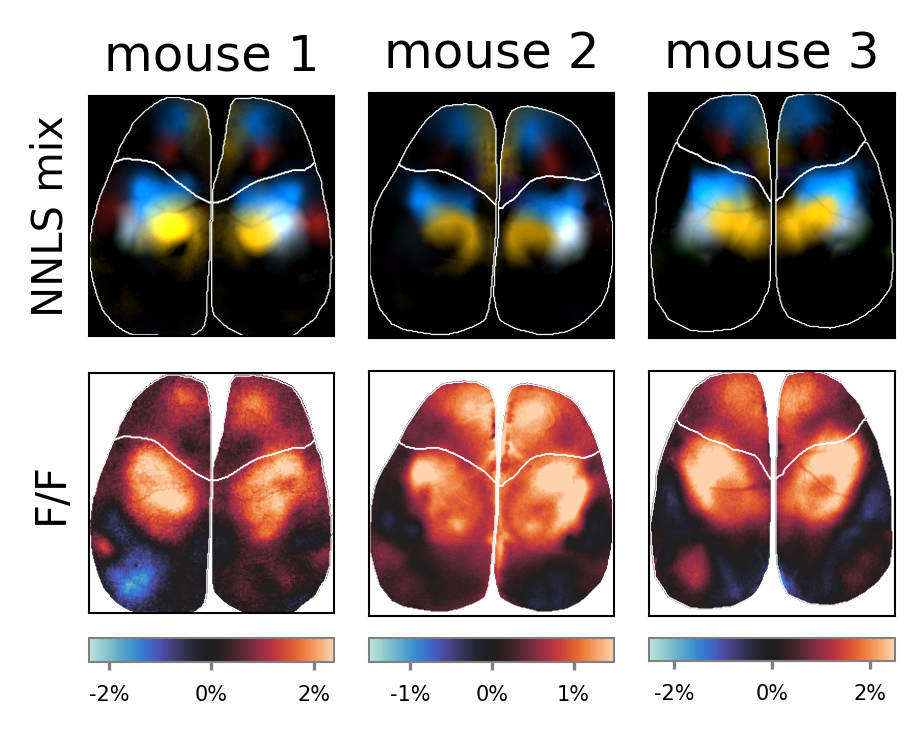

In [34]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;



x_start = x_offset
x_stop = x_start+4
y_start = y_offset
y_stop = y_start+4
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+4
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
    
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+1
for i_ax in range(3,6):
    exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
#===================
for i_mouse,mouse_id in enumerate(['cm229','cm126','cm128']):
    exec("ax{}.imshow(dict_blended_movie_per_mouse[mouse_id]['rise'])".format(i_mouse))
    if mouse_id == 'cm128':
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['rise'],vmin=-0.025,vmax=0.025,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    elif mouse_id == 'cm126':
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['rise'],vmin=-0.015,vmax=0.015,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    else:
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['rise'],vmin=-0.018,vmax=0.018,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    contours = dict_contours_per_mouse[mouse_id]
    for contour in contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))
    for contour in contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))




ax3.set_xlim([21,256]);ax3.set_ylim([248,18]);ax0.set_xlim([21,256]);ax0.set_ylim([248,18])#cm229
# ax4.set_xlim([19,256]);ax4.set_ylim([237,0]);ax1.set_xlim([19,256]);ax1.set_ylim([237,0])#cm241
# ax5.set_xlim([19,256]);ax5.set_ylim([237,0]);ax2.set_xlim([19,256]);ax2.set_ylim([237,0])#cm241
ax5.set_xlim([10,256]);ax5.set_ylim([246,0]);ax2.set_xlim([10,256]);ax2.set_ylim([246,0])#cm126
ax4.set_xlim([10,256]);ax4.set_ylim([256,10]);ax1.set_xlim([10,256]);ax1.set_ylim([256,10])#cm126


for i_ax in range(3,6):
    exec("cb = fig.colorbar(img{}, cax=ax99{},fraction=0.2,orientation='horizontal',format=FuncFormatter(fmt));".format(i_ax,i_ax))
    cb.ax.tick_params(labelsize=5,length=2,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(0.5)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    if i_ax ==5:
        exec("ax99{}.set_aspect(0.006*0.8)".format(i_ax))
    elif i_ax==4:
        exec("ax99{}.set_aspect(0.0037*0.8)".format(i_ax))
    elif i_ax==3:
        exec("ax99{}.set_aspect(0.0044*0.8)".format(i_ax))
    exec("ax99{}.set_anchor('N')".format(i_ax))


for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue 
            
ax0.set_title('mouse 1');ax1.set_title('mouse 2');ax2.set_title('mouse 3')

ax3.set_ylabel('F/F');#ax4.set_title('F/F');ax5.set_title('F/F')
ax0.set_ylabel('NNLS mix');

plt.subplots_adjust(wspace=1)
plt.savefig('fig7-integrated-part3A.svg',format='svg',dpi=300)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.1663351].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.2000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.1104876].


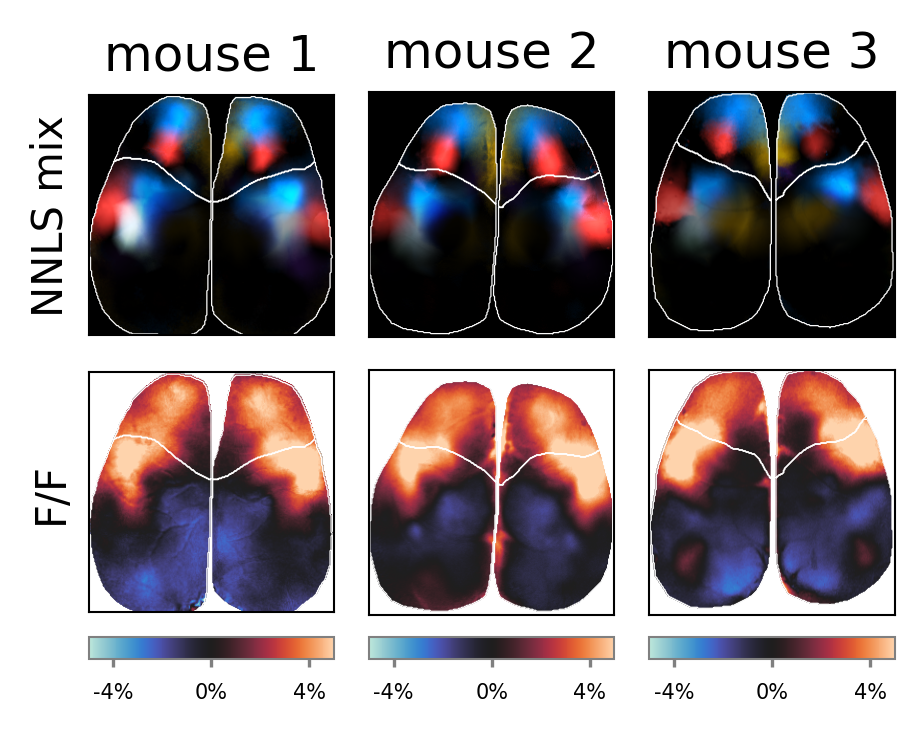

In [35]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;



x_start = x_offset
x_stop = x_start+4
y_start = y_offset
y_stop = y_start+4
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+4
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
    
x_start = x_offset
x_stop = x_start+4
y_start = y_stop
y_stop = y_start+1
for i_ax in range(3,6):
    exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+4
#===================
for i_mouse,mouse_id in enumerate(['cm229','cm126','cm128']):
    exec("ax{}.imshow(dict_blended_movie_per_mouse[mouse_id]['lick'])".format(i_mouse))
    if mouse_id == 'cm128':
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['lick'],vmin=-0.05,vmax=0.05,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    elif mouse_id == 'cm126':
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['lick'],vmin=-0.05,vmax=0.05,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    else:
        exec("img{} = ax{}.imshow(dict_AVG_full_jrgeco_2_save_per_mouse[mouse_id]['lick'],vmin=-0.05,vmax=0.05,cmap='icefire')".format(i_mouse+3,i_mouse+3))
    contours = dict_contours_per_mouse[mouse_id]
    for contour in contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))
    for contour in contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse))
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='white',alpha=0.99)".format(i_mouse+3))



ax3.set_xlim([21,256]);ax3.set_ylim([248,18]);ax0.set_xlim([21,256]);ax0.set_ylim([248,18])#cm229
# ax4.set_xlim([19,256]);ax4.set_ylim([237,0]);ax1.set_xlim([19,256]);ax1.set_ylim([237,0])#cm241
# ax5.set_xlim([19,256]);ax5.set_ylim([237,0]);ax2.set_xlim([19,256]);ax2.set_ylim([237,0])#cm241
ax5.set_xlim([10,256]);ax5.set_ylim([246,0]);ax2.set_xlim([10,256]);ax2.set_ylim([246,0])#cm126
ax4.set_xlim([10,256]);ax4.set_ylim([256,10]);ax1.set_xlim([10,256]);ax1.set_ylim([256,10])#cm126


for i_ax in range(3,6):
    exec("cb = fig.colorbar(img{}, cax=ax99{},fraction=0.2,orientation='horizontal',format=FuncFormatter(fmt));".format(i_ax,i_ax))
    cb.ax.tick_params(labelsize=5,length=2,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(0.5)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    # if i_ax ==5:
    #     exec("ax99{}.set_aspect(0.006)".format(i_ax))
    # elif i_ax==4:
    #     exec("ax99{}.set_aspect(0.0037)".format(i_ax))
    # elif i_ax==3:
    exec("ax99{}.set_aspect(0.01*0.9)".format(i_ax))
    exec("ax99{}.set_anchor('N')".format(i_ax))


for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue 
            
ax0.set_title('mouse 1');ax1.set_title('mouse 2');ax2.set_title('mouse 3')

ax3.set_ylabel('F/F');#ax4.set_title('F/F');ax5.set_title('F/F')
ax0.set_ylabel('NNLS mix');

plt.subplots_adjust(wspace=1)
plt.savefig('fig7-integrated-part3B.svg',format='svg',dpi=300)


# anatomical selectivity

In [38]:
import pandas as pd

# If not already defined
relevant_bdps = {
    "run": ["RFP", "LFP", "RHP", "LHP"],
    "lick": ["LM", "RM"],
    "integrated": ["LM", "RM", "RFP", "LFP"]
}

# Function to label relevant vs non-relevant
def assign_relevance(row):
    rel_bdps = relevant_bdps.get(row["movement_type"], [])
    return "Relevant" if row["bdp"] in rel_bdps else "Non-Relevant"

# Label relevance
GRAND_DF["bdp_category"] = GRAND_DF.apply(assign_relevance, axis=1)

# Group to compute mean per bout per category
grouped = (
    GRAND_DF
    .groupby(["mouse_id", "region", "movement_type", "bout", "bdp_category"])["value"]
    .mean()
    .reset_index()
)

# Pivot so Relevant and Non-Relevant are columns
pivoted = (
    grouped
    .pivot_table(
        index=["mouse_id", "region", "movement_type", "bout"],
        columns="bdp_category",
        values="value"
    )
    .reset_index()
)

# Compute selectivity score
pivoted["selectivity"] = pivoted["Relevant"] - pivoted["Non-Relevant"]

# Inspect
pivoted.head()


bdp_category,mouse_id,region,movement_type,bout,Non-Relevant,Relevant,selectivity
0,cm125,M1,run,0,NaN,0.092228,NaN
1,cm125,M1,run,1,NaN,0.071844,NaN
2,cm125,M1,run,2,NaN,0.072484,NaN
3,cm125,M1,run,3,NaN,0.050265,NaN
4,cm125,M1,run,4,NaN,0.060324,NaN


In [39]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Mann-Whitney U (run vs lick, run vs integrated), Bonferroni-corrected across all 4 tests.
# Replaces the broken statannot.add_stat_annotation call above (AttributeError on this
# seaborn version: 'seaborn.categorical' has no attribute '_BoxPlotter').
movement_order = ["run", "lick", "integrated"]
comparisons = [("run", "lick"), ("run", "integrated")]

keys, raw_ps, ns = [], [], []
for region in ["M2", "S1"]:
    sub = pivoted[pivoted["region"] == region]
    for a, b in comparisons:
        xa = sub[sub.movement_type == a]["selectivity"].dropna().values
        xb = sub[sub.movement_type == b]["selectivity"].dropna().values
        _, p = mannwhitneyu(xa, xb, alternative="two-sided")
        keys.append((region, a, b))
        raw_ps.append(p)
        ns.append((len(xa), len(xb)))

_, p_bonf, _, _ = multipletests(raw_ps, method="bonferroni")

pvals = {"M2": {}, "S1": {}}
for (region, a, b), p_raw, p_adj, (na, nb) in zip(keys, raw_ps, p_bonf, ns):
    pvals[region][(a, b)] = p_adj
    print(f"{region:2s}  {a} vs {b:11s}  n={na},{nb}  p_raw={p_raw:.3e}  p_bonferroni={p_adj:.3e}")


M2  run vs lick         n=191,43  p_raw=2.419e-02  p_bonferroni=9.676e-02
M2  run vs integrated   n=191,38  p_raw=2.452e-06  p_bonferroni=9.808e-06
S1  run vs lick         n=191,43  p_raw=1.641e-18  p_bonferroni=6.566e-18
S1  run vs integrated   n=191,38  p_raw=1.932e-12  p_bonferroni=7.728e-12


In [40]:
def new_adjust_box_widths(axes, fac=0.9):
    """
    Adjust the widths of a seaborn-generated boxplot or boxenplot.
    
    Notes
    -----
    - thanks https://github.com/mwaskom/seaborn/issues/1076
    """
    from matplotlib.patches import PathPatch
    from matplotlib.collections import PatchCollection
    
    if isinstance(axes, list) is False:
        axes = [axes]

        
    x_offsets = [-0.8, 0.8]  # Adjust these values to control the separation between hue categories


    display_coordinates_1=[]
    display_coordinates_2=[]
        
        
    # iterating through Axes instances
    for ax in axes:

        # iterating through axes artists:
        for c in ax.get_children():
            # searching for PathPatches
            if isinstance(c, PathPatch) or isinstance(c, PatchCollection):
                if isinstance(c, PathPatch):
                    p = c.get_path()
                    x0_here = c.get_extents().x0
                else:
                    p = c.get_paths()[-1]
                    print('hii')
                    

        
                # getting current width of box:
#                 p = c.get_path()
                verts = p.vertices
                verts_sub = verts[:-1]
                xmin = np.min(verts_sub[:, 0])
                xmax = np.max(verts_sub[:, 0])
                xmid = 0.5 * (xmin + xmax)
                xhalf = 0.5 * (xmax - xmin)

                # setting new width of box
                xmin_new = xmid - fac * xhalf
                xmax_new = xmid + fac * xhalf
                verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
                verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new

                # setting new width of median line
                for l in ax.lines:
                    try:
                        if np.all(l.get_xdata() == [xmin, xmax]):
                            l.set_xdata([xmin_new, xmax_new])
                    except:
                        # /tmp/ipykernel_138835/916607433.py:32: DeprecationWarning: elementwise comparison failed;
                            # this will raise an error in the future.
                                # if np.all(l.get_xdata() == [xmin, xmax]):
                        pass
    pass

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/474067170.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/474067170.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/474067170.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_91220/474067170.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated

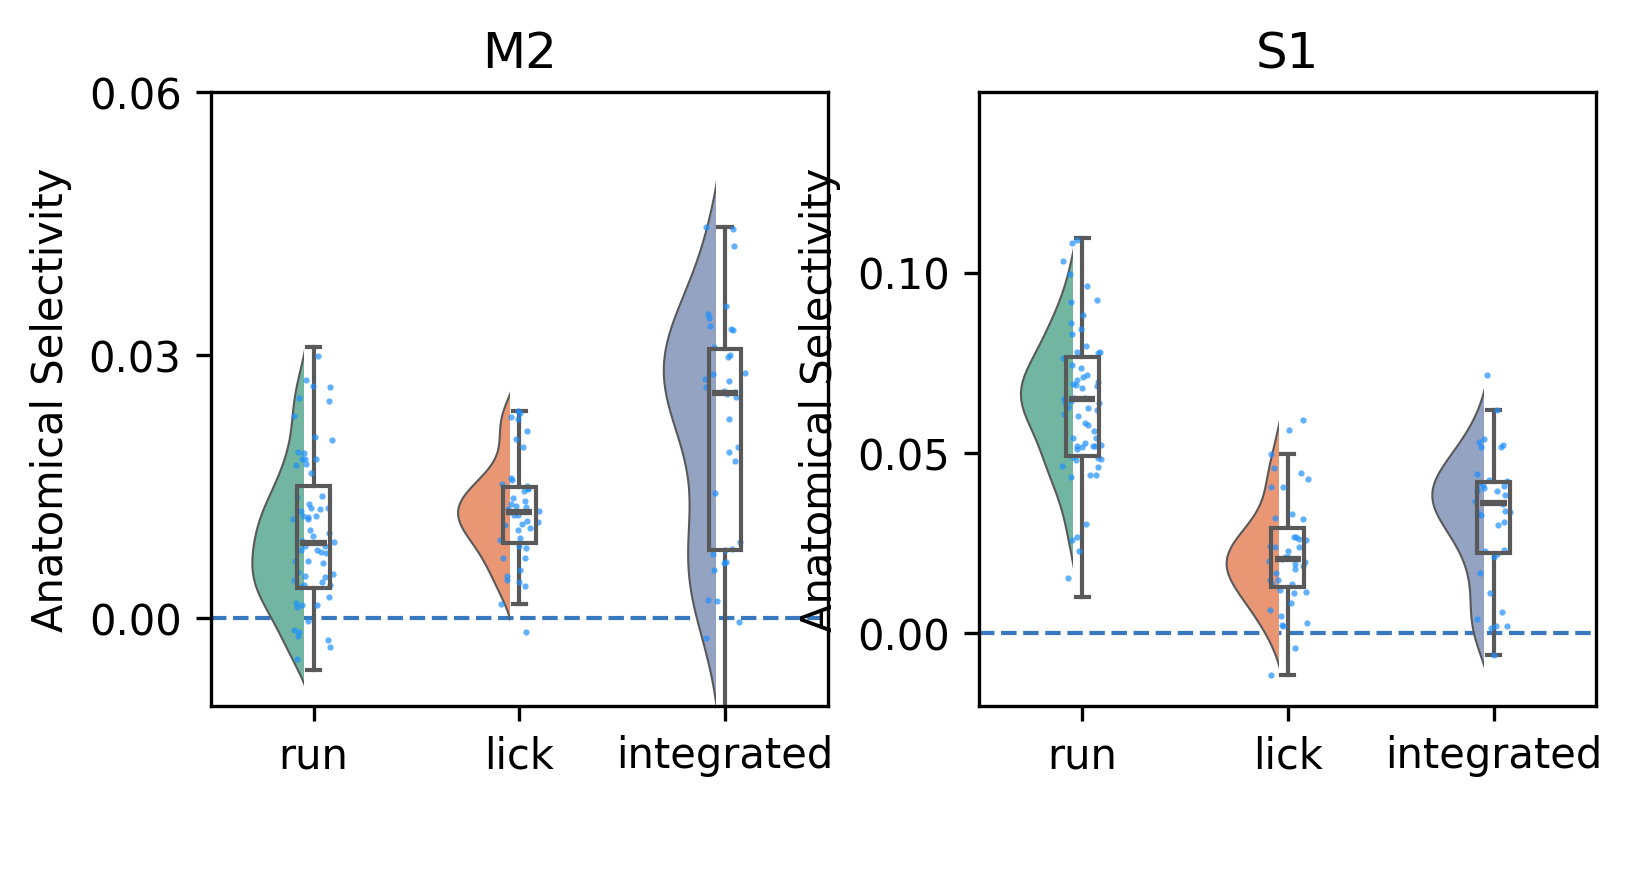

In [41]:
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- Setup ---
movement_order = ["run", "lick", "integrated"]
region_order = ["M2", "S1"]
my_pal = {"run": "#66c2a5", "lick": "#fc8d62", "integrated": "#8da0cb"}

# Set up figure
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
gs = GridSpec(100, 100)
fig = plt.figure(figsize=(30, 30), dpi=300)

# Iterate over regions
x_start = 20 
x_stop = x_start + 9
for r_i, region in enumerate(region_order):
    ax = fig.add_subplot(gs[20:29, x_start:x_stop])
    x_start = x_stop + 2
    x_stop = x_start + 9
    
    data = pivoted[pivoted["region"] == region]

    # Violin
    sns.violinplot(
        x="movement_type", y="selectivity", data=data,
        order=movement_order, palette=my_pal,
        density_norm="width", width=0.6,  # ← adjust this (default is 0.8)
        linewidth=0.5, inner=None, ax=ax
    )
    for violin in ax.collections:
        bbox = violin.get_paths()[0].get_extents()
        x0, y0, width, height = bbox.bounds
        violin.set_clip_path(plt.Rectangle((x0 - 0.05, y0), width / 2, height, transform=ax.transData))

    sns.boxplot(
        x="movement_type", y="selectivity", data=data,
        order=movement_order, palette=my_pal,
        showfliers=False, linewidth=1,
        boxprops={'zorder': 6, 'facecolor': 'none'},
        whiskerprops={'linewidth': 1, 'solid_capstyle': 'projecting'},
        capprops={'linewidth': 1, 'solid_capstyle': 'projecting'},
        medianprops={'zorder': 7, 'linewidth': 1.5},
        ax=ax
    )
    
    # Manually shorten cap lines
    for line in ax.lines:
        xdata = line.get_xdata()
        ydata = line.get_ydata()
        if len(xdata) == 2 and xdata[0] != xdata[1] and ydata[0] == ydata[1]:
            xmid = np.mean(xdata)
            width = (xdata[1] - xdata[0]) * 0.4  # reduce cap width to 40%
            line.set_xdata([xmid - width / 2, xmid + width / 2])
    # Shorten horizontal median lines
    for line in ax.lines:
        xdata = line.get_xdata()
        ydata = line.get_ydata()

        # Identify horizontal lines
        if len(xdata) == 2 and ydata[0] == ydata[1]:
            width = (xdata[1] - xdata[0]) * 0.4  # shrink to 40%
            xmid = np.mean(xdata)
            line.set_xdata([xmid - width / 2, xmid + width / 2])
        
    new_adjust_box_widths(ax, fac=0.2)

    
    
    
    # Strip

    # Separate the 'run' data from the rest
    run_data = data[data['movement_type'] == 'run']
    other_data = data[data['movement_type'] != 'run']

    # Randomly sample 1/3 of the 'run' data
    # The frac=1/3 argument specifies the fraction of items to return.
    run_downsampled = run_data.sample(frac=1/3, random_state=42) # random_state for reproducibility

    # Combine the downsampled 'run' data with the other data
    downsampled_df = pd.concat([run_downsampled, other_data]).sort_index()

    sns.stripplot(
        x="movement_type", y="selectivity", data=downsampled_df,
        order=movement_order, color='dodgerblue',
        size=1.5, alpha=0.7, jitter=True, ax=ax
    )


    # Stat annotations
    ax.axhline(0, color='#3778bf', linewidth=1, linestyle='dashed', zorder=0)
    ax.set_title(region)
    ax.set_xlabel("")
    ax.set_ylabel("Anatomical Selectivity")
    if region == "M2":
        ax.set_ylim([-0.01, 0.06])
        ax.set_yticks([0,0.03,0.06])
    elif region == "S1":
        ax.set_ylim([-0.02, 0.15])
        ax.set_yticks([0,0.05,0.1])
    
    


# Save figure
plt.savefig("fig7-anatomical_selectivity_stats.svg", format='svg', dpi=300)
